In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 130,
    'figure.facecolor': 'white',
    'axes.facecolor': '#f8f9fa',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.4,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

SAFE_CLR   = '#2196F3'
ALERT_CLR  = '#FF9800'
RISK_CLR   = '#F44336'
SITE1_CLR  = '#1565C0'
SITE2_CLR  = '#E65100'
RISK_ORDER = ['Safe/Normal (<=260)', 'Elevated/Alert (261-540)', 'High-Risk (>540)']
RISK_COLORS= [SAFE_CLR, ALERT_CLR, RISK_CLR]

THRESH_ALERT = 260
THRESH_RISK  = 540

df = pd.read_excel('/mnt/data/Ecoli and LagRainfall(1).xlsx')
df['DateTime'] = pd.to_datetime(df['DateTime'])
df = df.sort_values('DateTime').reset_index(drop=True)

print(f"Rows: {len(df)}  |  Columns: {df.shape[1]}")
print(f"Date range: {df['DateTime'].min().date()} to {df['DateTime'].max().date()}")
print(f"Sites: {df['Site'].unique().tolist()}")


Rows: 203  |  Columns: 18
Date range: 2021-01-04 to 2026-04-30
Sites: ['Oroua at Almadale', 'Oroua at Almadale Slackline']


In [2]:
display(df.head(8))


,Site,DateTime,Ecoli_MPN_100mL,Log10_Ecoli,Rain_Day0_Calendar_mm,Rain_Lag1d_mm,Rain_Lag2d_mm,Rain_Lag3d_mm,Rain_Lag4d_mm,Rain_Lag5d_mm,Rain_Lag6d_mm,Rain_Lag7d_mm,Rain_Pre6h_mm,Rain_Pre12h_mm,Rain_Pre24h_mm,Rain_Pre48h_mm,Rain_Pre72h_mm,Rain_Pre7d_mm
0,Oroua at Almadale,2021-01-04 08:11:00.000,24200.0,4.383815,26.36,0.00,0.00,0.00,0.00,0.00,4.09,4.09,3.5,5.0,33.5,34.0,34.0,34.0
1,Oroua at Almadale,2021-01-10 12:24:00.000,41.0,1.612784,0.00,6.82,2.73,0.00,0.00,5.46,26.36,0.00,0.0,0.0,0.0,3.0,10.5,44.5
2,Oroua at Almadale,2021-01-18 10:58:00.000,374.0,2.572872,9.55,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.5,4.0,13.5,14.5,14.5,14.5
3,Oroua at Almadale Slackline,2021-01-21 09:00:00.000,1700.0,3.230449,14.55,4.55,6.82,9.55,0.00,0.00,0.00,0.00,0.0,0.0,15.0,21.0,24.5,39.0
4,Oroua at Almadale,2021-01-24 10:44:59.999,63.0,1.799341,0.91,1.82,0.91,14.55,4.55,6.82,9.55,0.00,2.0,7.0,7.0,8.0,11.0,49.0
5,Oroua at Almadale,2021-02-02 08:38:00.000,98.0,1.991226,0.00,0.00,0.00,0.00,1.36,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,1.5
6,Oroua at Almadale,2021-02-07 11:04:00.000,9.0,0.954243,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0
7,Oroua at Almadale,2021-02-15 10:55:00.000,231.0,2.363612,0.00,0.00,0.00,0.00,4.55,0.00,0.00,0.00,0.5,0.5,0.5,0.5,0.5,5.5


In [3]:
summary = pd.DataFrame({
    'dtype':   df.dtypes,
    'non_null': df.notnull().sum(),
    'null':     df.isnull().sum(),
    'null_%':  (df.isnull().mean() * 100).round(1)
})
display(summary)

print()
print("NOTE: Rain_Day0_Calendar_mm and Lag1-Lag7 have 52 nulls.")
print("      These are records from Jan 2025 onward where daily rainfall")
print("      data was not available. Antecedent window columns (Pre6h-Pre7d)")
print("      are complete for all 203 rows and are leakage-safe.")


,dtype,non_null,null,null_%
Site,object,203,0,0.0
DateTime,datetime64[ns],203,0,0.0
Ecoli_MPN_100mL,float64,203,0,0.0
Log10_Ecoli,float64,203,0,0.0
Rain_Day0_Calendar_mm,float64,151,52,25.6
Rain_Lag1d_mm,float64,151,52,25.6
Rain_Lag2d_mm,float64,151,52,25.6
Rain_Lag3d_mm,float64,151,52,25.6
Rain_Lag4d_mm,float64,151,52,25.6
Rain_Lag5d_mm,float64,151,52,25.6



NOTE: Rain_Day0_Calendar_mm and Lag1-Lag7 have 52 nulls.
      These are records from Jan 2025 onward where daily rainfall
      data was not available. Antecedent window columns (Pre6h-Pre7d)
      are complete for all 203 rows and are leakage-safe.


In [4]:
rain_cols = [c for c in df.columns if 'Rain' in c and c != 'Rain_Day0_Calendar_mm']
display(df[['Ecoli_MPN_100mL', 'Log10_Ecoli'] + rain_cols].describe().round(2))


,Ecoli_MPN_100mL,Log10_Ecoli,Rain_Lag1d_mm,Rain_Lag2d_mm,Rain_Lag3d_mm,Rain_Lag4d_mm,Rain_Lag5d_mm,Rain_Lag6d_mm,Rain_Lag7d_mm,Rain_Pre6h_mm,Rain_Pre12h_mm,Rain_Pre24h_mm,Rain_Pre48h_mm,Rain_Pre72h_mm,Rain_Pre7d_mm
count,203.00,203.00,151.00,151.00,151.00,151.00,151.00,151.00,151.00,203.00,203.00,203.00,203.00,203.00,203.00
mean,583.55,2.21,3.70,4.49,3.32,3.80,3.53,3.90,3.35,0.61,1.30,3.54,7.93,12.64,28.35
std,1993.23,0.61,6.77,8.55,5.98,8.10,8.36,9.97,7.65,1.49,2.79,6.65,12.37,17.90,29.35
min,4.00,0.60,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,64.40,1.81,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,8.50
50%,144.00,2.16,0.45,0.44,0.00,0.40,0.00,0.00,0.00,0.00,0.00,0.00,3.00,6.50,22.50
75%,315.50,2.50,4.42,5.63,3.73,3.24,3.20,4.10,3.68,0.50,1.00,4.75,11.25,17.00,38.00
max,24200.00,4.38,40.74,52.52,26.83,43.60,68.58,99.57,56.50,9.00,16.00,35.00,84.50,138.00,182.00


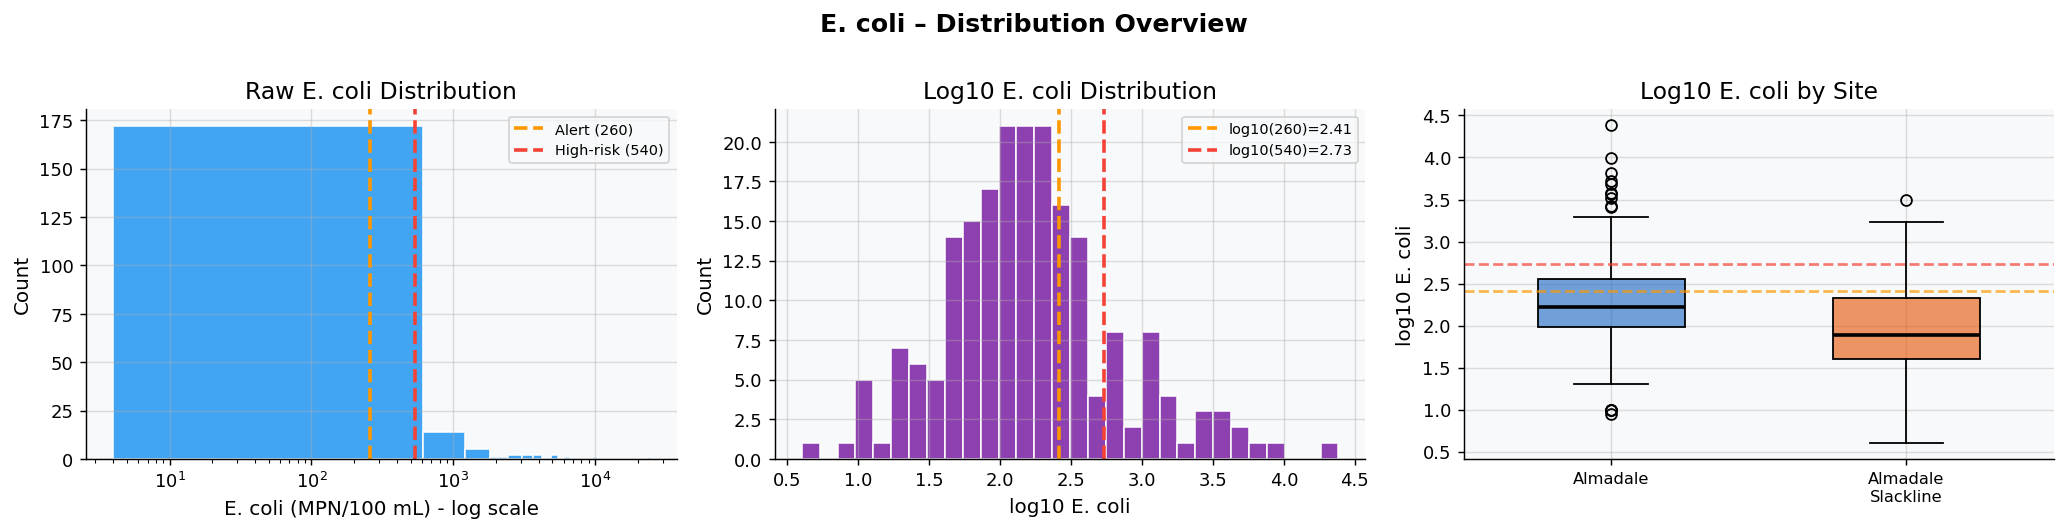

Median E. coli : 144 MPN/100 mL
Mean   E. coli : 584 MPN/100 mL  (skewed by extremes)
Max    E. coli : 24200 MPN/100 mL
Geometric mean : 161 MPN/100 mL


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

ax = axes[0]
ax.hist(df['Ecoli_MPN_100mL'], bins=40, color=SAFE_CLR, edgecolor='white', alpha=0.85)
ax.axvline(THRESH_ALERT, color=ALERT_CLR, lw=2, ls='--', label=f'Alert ({THRESH_ALERT})')
ax.axvline(THRESH_RISK,  color=RISK_CLR,  lw=2, ls='--', label=f'High-risk ({THRESH_RISK})')
ax.set_xscale('log')
ax.set_xlabel('E. coli (MPN/100 mL) - log scale')
ax.set_ylabel('Count')
ax.set_title('Raw E. coli Distribution')
ax.legend(fontsize=8)

ax = axes[1]
ax.hist(df['Log10_Ecoli'], bins=30, color='#7B1FA2', edgecolor='white', alpha=0.85)
ax.axvline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=2, ls='--',
           label=f'log10({THRESH_ALERT})={np.log10(THRESH_ALERT):.2f}')
ax.axvline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=2, ls='--',
           label=f'log10({THRESH_RISK})={np.log10(THRESH_RISK):.2f}')
ax.set_xlabel('log10 E. coli')
ax.set_ylabel('Count')
ax.set_title('Log10 E. coli Distribution')
ax.legend(fontsize=8)

ax = axes[2]
site_data = [df.loc[df['Site'] == s, 'Log10_Ecoli'].values for s in df['Site'].unique()]
bp = ax.boxplot(site_data, patch_artist=True, widths=0.5,
                medianprops=dict(color='black', lw=2))
bp['boxes'][0].set_facecolor(SITE1_CLR + '99')
bp['boxes'][1].set_facecolor(SITE2_CLR + '99')
ax.set_xticklabels(['Almadale', 'Almadale\nSlackline'], fontsize=9)
ax.set_ylabel('log10 E. coli')
ax.set_title('Log10 E. coli by Site')
ax.axhline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.5, ls='--', alpha=0.7)
ax.axhline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.5, ls='--', alpha=0.7)

plt.suptitle('E. coli – Distribution Overview', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig01_ecoli_distribution.png', bbox_inches='tight')
plt.show()

print(f"Median E. coli : {df['Ecoli_MPN_100mL'].median():.0f} MPN/100 mL")
print(f"Mean   E. coli : {df['Ecoli_MPN_100mL'].mean():.0f} MPN/100 mL  (skewed by extremes)")
print(f"Max    E. coli : {df['Ecoli_MPN_100mL'].max():.0f} MPN/100 mL")
print(f"Geometric mean : {10**df['Log10_Ecoli'].mean():.0f} MPN/100 mL")


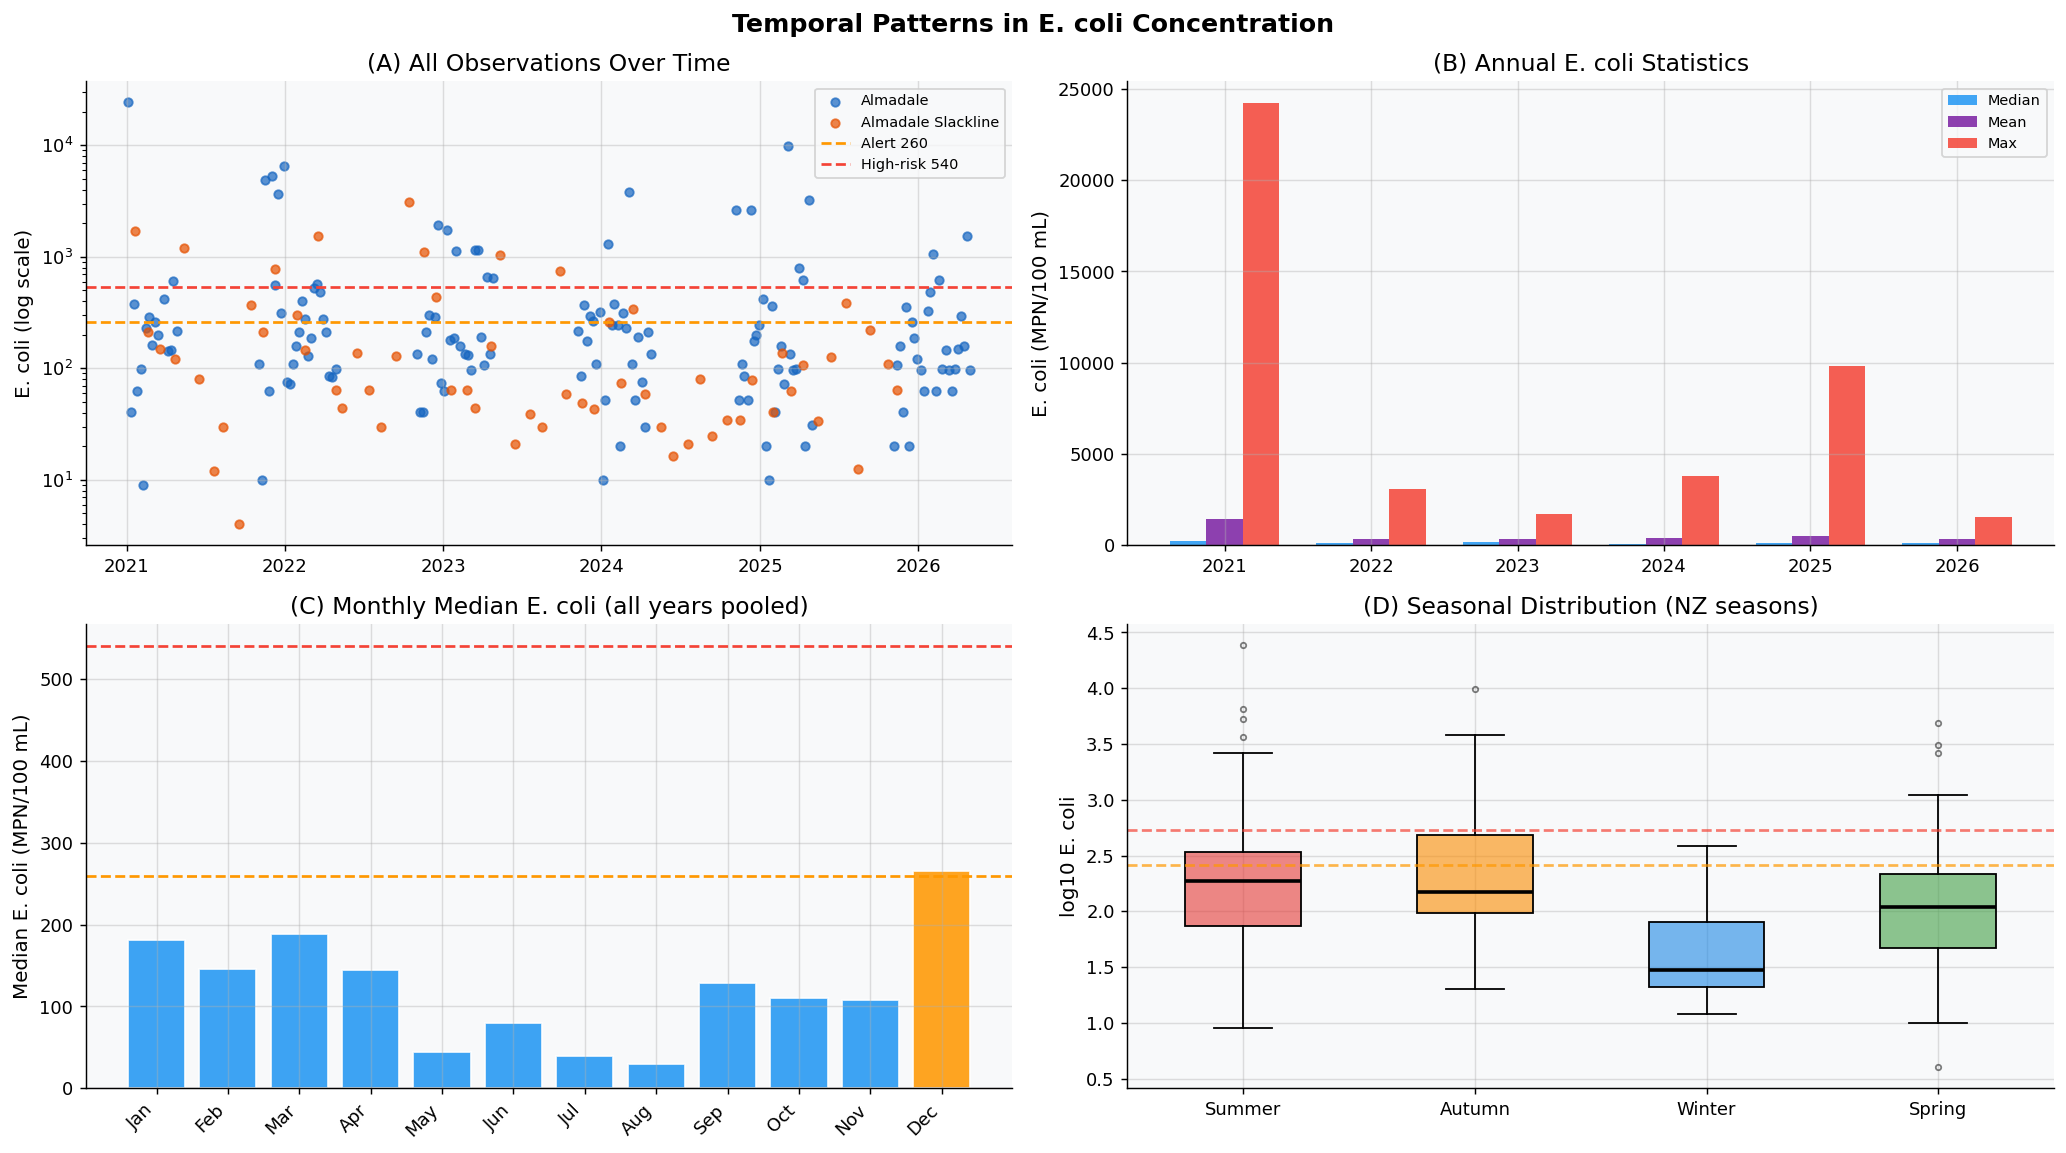

In [6]:
df['Year']     = df['DateTime'].dt.year
df['Month']    = df['DateTime'].dt.month
df['Month_nm'] = df['DateTime'].dt.strftime('%b')
df['Season']   = df['Month'].map({
    12:'Summer', 1:'Summer', 2:'Summer',
    3:'Autumn',  4:'Autumn', 5:'Autumn',
    6:'Winter',  7:'Winter', 8:'Winter',
    9:'Spring', 10:'Spring', 11:'Spring'
})

fig, axes = plt.subplots(2, 2, figsize=(16, 9))

ax = axes[0, 0]
for site, clr in zip(df['Site'].unique(), [SITE1_CLR, SITE2_CLR]):
    sub = df[df['Site'] == site]
    ax.scatter(sub['DateTime'], sub['Ecoli_MPN_100mL'],
               color=clr, s=22, alpha=0.7, label=site.replace('Oroua at ', ''))
ax.axhline(THRESH_ALERT, color=ALERT_CLR, lw=1.5, ls='--', label='Alert 260')
ax.axhline(THRESH_RISK,  color=RISK_CLR,  lw=1.5, ls='--', label='High-risk 540')
ax.set_yscale('log')
ax.set_ylabel('E. coli (log scale)')
ax.set_title('(A) All Observations Over Time')
ax.legend(fontsize=8)

ax = axes[0, 1]
annual = df.groupby('Year')['Ecoli_MPN_100mL'].agg(['median','mean','max']).reset_index()
w = 0.25
x = np.arange(len(annual))
ax.bar(x-w, annual['median'], width=w, label='Median', color=SAFE_CLR, alpha=0.85)
ax.bar(x,   annual['mean'],   width=w, label='Mean',   color='#7B1FA2', alpha=0.85)
ax.bar(x+w, annual['max'],    width=w, label='Max',    color=RISK_CLR,  alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(annual['Year'])
ax.set_ylabel('E. coli (MPN/100 mL)')
ax.set_title('(B) Annual E. coli Statistics')
ax.legend(fontsize=8)

ax = axes[1, 0]
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly = df.groupby('Month_nm')['Ecoli_MPN_100mL'].median().reindex(month_order)
colors_m = [RISK_CLR if v > THRESH_RISK else (ALERT_CLR if v > THRESH_ALERT else SAFE_CLR)
            for v in monthly]
ax.bar(range(12), monthly.values, color=colors_m, edgecolor='white', alpha=0.87)
ax.axhline(THRESH_ALERT, color=ALERT_CLR, lw=1.5, ls='--')
ax.axhline(THRESH_RISK,  color=RISK_CLR,  lw=1.5, ls='--')
ax.set_xticks(range(12))
ax.set_xticklabels(month_order, rotation=45, ha='right')
ax.set_ylabel('Median E. coli (MPN/100 mL)')
ax.set_title('(C) Monthly Median E. coli (all years pooled)')

ax = axes[1, 1]
season_order  = ['Summer','Autumn','Winter','Spring']
season_colors = ['#E53935','#FB8C00','#1E88E5','#43A047']
for i, (seas, clr) in enumerate(zip(season_order, season_colors)):
    sub = df[df['Season'] == seas]['Log10_Ecoli']
    bp = ax.boxplot(sub, positions=[i], patch_artist=True, widths=0.5,
                    medianprops=dict(color='black', lw=2),
                    flierprops=dict(marker='o', markersize=3, alpha=0.5))
    bp['boxes'][0].set_facecolor(clr + '99')
ax.axhline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.5, ls='--', alpha=0.7)
ax.axhline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.5, ls='--', alpha=0.7)
ax.set_xticks(range(4))
ax.set_xticklabels(season_order)
ax.set_ylabel('log10 E. coli')
ax.set_title('(D) Seasonal Distribution (NZ seasons)')

plt.suptitle('Temporal Patterns in E. coli Concentration', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig02_temporal.png', bbox_inches='tight')
plt.show()


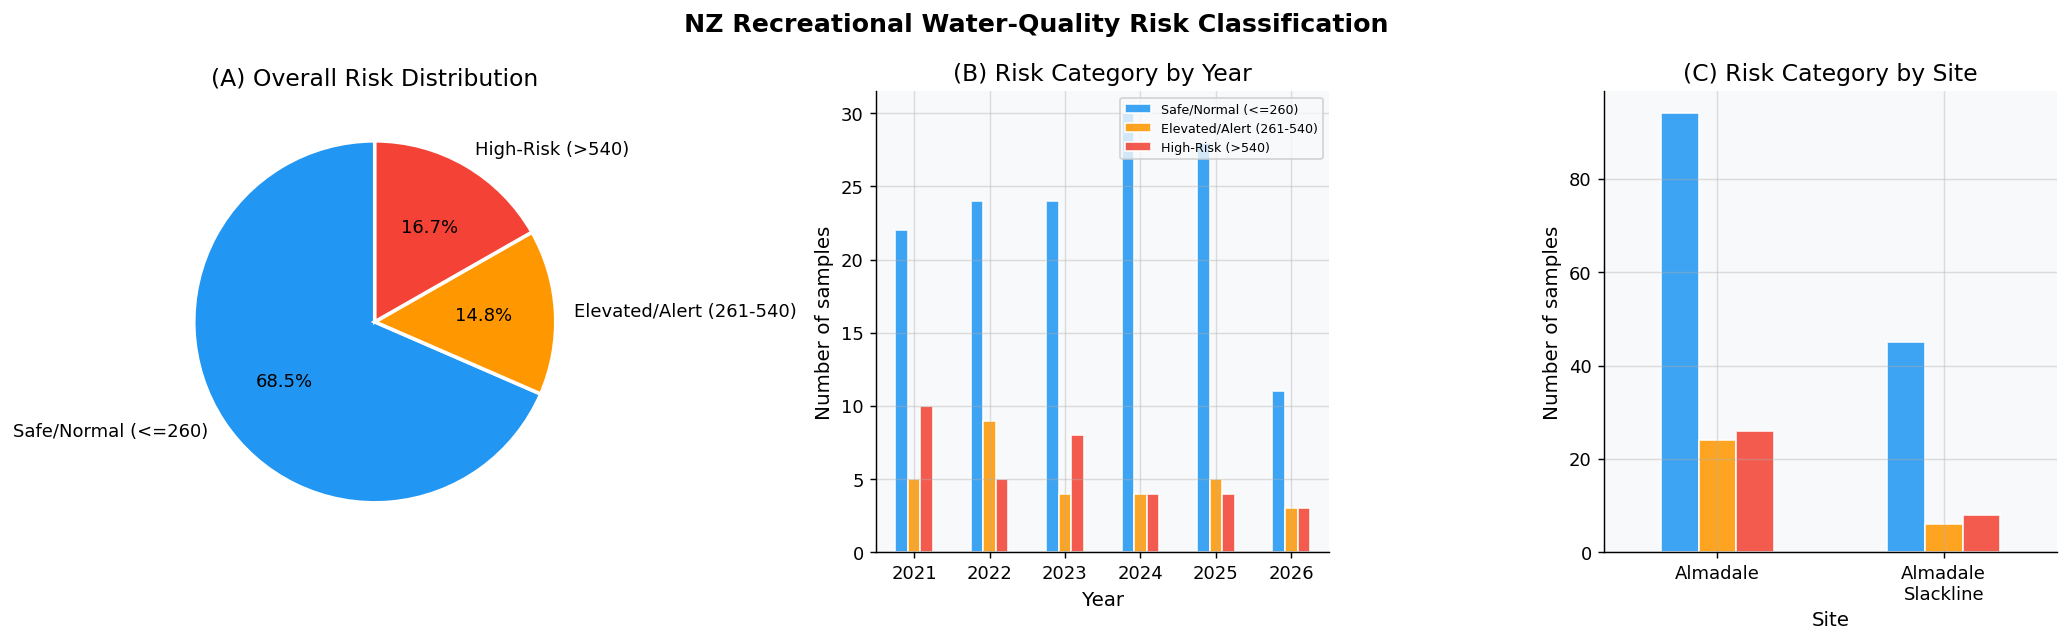

Risk category summary:
                          Count  Percentage (%)
Risk_Label                                     
Safe/Normal (<=260)         139            68.5
Elevated/Alert (261-540)     30            14.8
High-Risk (>540)             34            16.7


In [7]:
def classify_risk(val):
    if val <= THRESH_ALERT:   return 'Safe/Normal (<=260)'
    elif val <= THRESH_RISK:  return 'Elevated/Alert (261-540)'
    else:                     return 'High-Risk (>540)'

df['Risk_Label'] = df['Ecoli_MPN_100mL'].apply(classify_risk)
risk_counts = df['Risk_Label'].value_counts().reindex(RISK_ORDER)
pct = (risk_counts / len(df) * 100).round(1)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ax = axes[0]
wedges, texts, autotexts = ax.pie(
    risk_counts, labels=RISK_ORDER, colors=RISK_COLORS,
    autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2))
for at in autotexts: at.set_fontsize(10)
ax.set_title('(A) Overall Risk Distribution')

ax = axes[1]
yr_risk = df.groupby(['Year','Risk_Label']).size().unstack(fill_value=0).reindex(columns=RISK_ORDER)
yr_risk.plot(kind='bar', ax=ax, color=RISK_COLORS, edgecolor='white', alpha=0.87, legend=False)
ax.set_xticklabels(yr_risk.index, rotation=0)
ax.set_ylabel('Number of samples')
ax.set_title('(B) Risk Category by Year')
ax.legend(RISK_ORDER, fontsize=7, loc='upper right')

ax = axes[2]
site_risk = df.groupby(['Site','Risk_Label']).size().unstack(fill_value=0).reindex(columns=RISK_ORDER)
site_risk.plot(kind='bar', ax=ax, color=RISK_COLORS, edgecolor='white', alpha=0.87, legend=False)
ax.set_xticklabels(['Almadale','Almadale\nSlackline'], rotation=0)
ax.set_ylabel('Number of samples')
ax.set_title('(C) Risk Category by Site')

plt.suptitle('NZ Recreational Water-Quality Risk Classification', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig03_risk_classification.png', bbox_inches='tight')
plt.show()

print("Risk category summary:")
print(pd.DataFrame({'Count': risk_counts, 'Percentage (%)': pct}).to_string())


Rows used for daily lag analysis: 151  (post-2025 NaN rows excluded)


,Lag,Pearson_r,p_value,CI_lower,CI_upper,Significant
0,Lag 1d,0.2112,0.0092,0.0533,0.3588,True
1,Lag 2d,0.1666,0.0409,0.0071,0.3179,True
2,Lag 3d,0.0266,0.7458,-0.1337,0.1855,False
3,Lag 4d,0.0688,0.4010,-0.0919,0.2261,False
4,Lag 5d,-0.0057,0.9446,-0.1653,0.1542,False
5,Lag 6d,-0.0648,0.4290,-0.2223,0.0959,False
6,Lag 7d,-0.0437,0.5939,-0.2020,0.1168,False


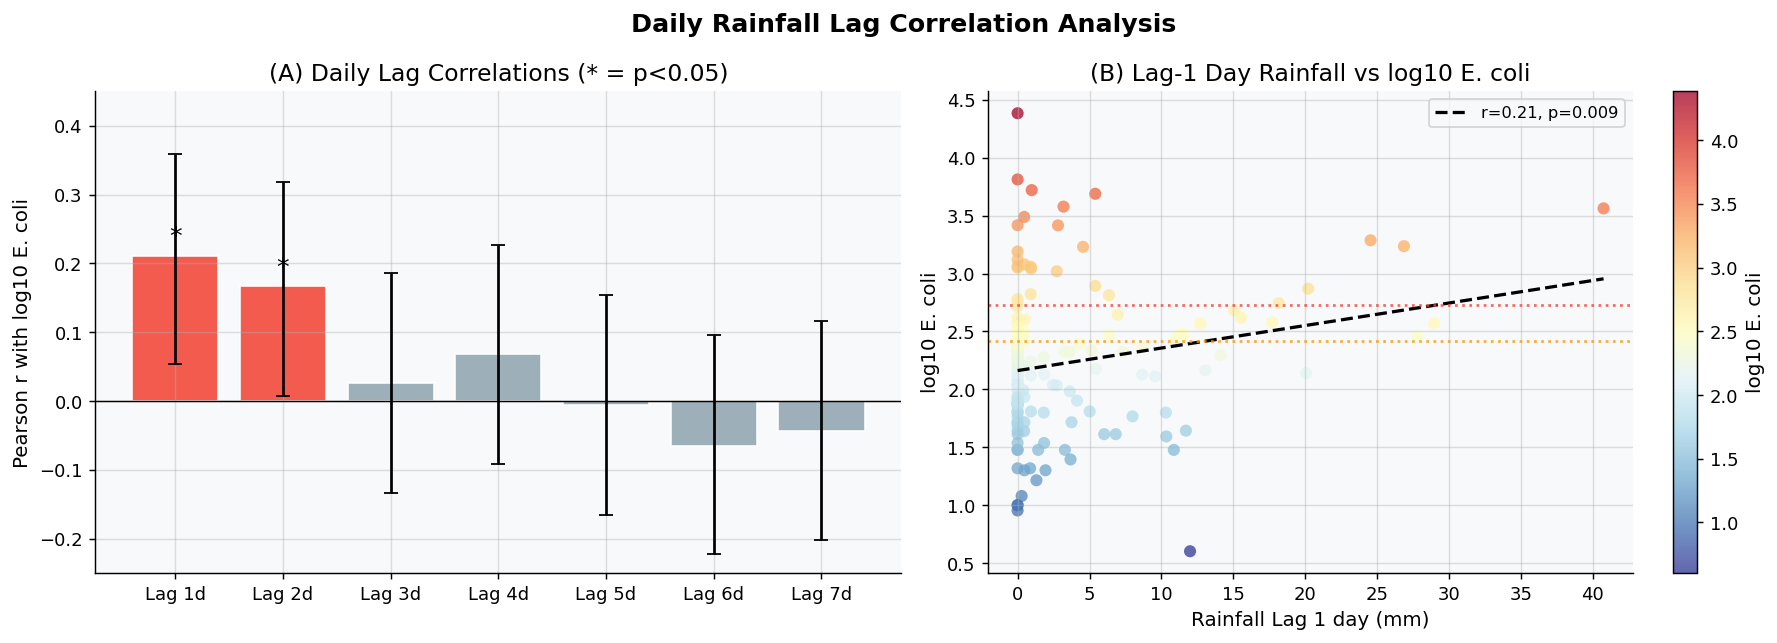

In [8]:
lag_cols   = [f'Rain_Lag{i}d_mm' for i in range(1, 8)]
lag_labels = [f'Lag {i}d' for i in range(1, 8)]

df_lag = df[lag_cols + ['Log10_Ecoli']].dropna()
print(f"Rows used for daily lag analysis: {len(df_lag)}  (post-2025 NaN rows excluded)")

pearson_r, pearson_p, ci_lo, ci_hi = [], [], [], []
for col in lag_cols:
    r, p = stats.pearsonr(df_lag[col], df_lag['Log10_Ecoli'])
    n = len(df_lag)
    z  = np.arctanh(r); se = 1/np.sqrt(n-3)
    pearson_r.append(r); pearson_p.append(p)
    ci_lo.append(np.tanh(z - 1.96*se))
    ci_hi.append(np.tanh(z + 1.96*se))

corr_df = pd.DataFrame({
    'Lag': lag_labels, 'Pearson_r': pearson_r, 'p_value': pearson_p,
    'CI_lower': ci_lo, 'CI_upper': ci_hi,
    'Significant': [p < 0.05 for p in pearson_p]
})
display(corr_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
colors_lag = [RISK_CLR if sig else '#90A4AE' for sig in corr_df['Significant']]
bars = ax.bar(lag_labels, corr_df['Pearson_r'], color=colors_lag, edgecolor='white', alpha=0.87)
err_lo = corr_df['Pearson_r'] - corr_df['CI_lower']
err_hi = corr_df['CI_upper']  - corr_df['Pearson_r']
ax.errorbar(lag_labels, corr_df['Pearson_r'],
            yerr=[err_lo, err_hi], fmt='none', color='black', capsize=4, lw=1.5)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Pearson r with log10 E. coli')
ax.set_title('(A) Daily Lag Correlations (* = p<0.05)')
ax.set_ylim(-0.25, 0.45)
for bar, sig in zip(bars, corr_df['Significant']):
    if sig:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01, '*', ha='center', va='bottom', fontsize=14)

ax = axes[1]
sub = df_lag.dropna(subset=['Rain_Lag1d_mm'])
sc = ax.scatter(sub['Rain_Lag1d_mm'], sub['Log10_Ecoli'],
                c=sub['Log10_Ecoli'], cmap='RdYlBu_r', s=45, alpha=0.75, edgecolors='none')
m, b, r, p, _ = stats.linregress(sub['Rain_Lag1d_mm'], sub['Log10_Ecoli'])
x_rng = np.linspace(sub['Rain_Lag1d_mm'].min(), sub['Rain_Lag1d_mm'].max(), 100)
ax.plot(x_rng, m*x_rng + b, 'k--', lw=1.8, label=f'r={r:.2f}, p={p:.3f}')
ax.axhline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.5, ls=':', alpha=0.8)
ax.axhline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.5, ls=':', alpha=0.8)
ax.set_xlabel('Rainfall Lag 1 day (mm)')
ax.set_ylabel('log10 E. coli')
ax.set_title('(B) Lag-1 Day Rainfall vs log10 E. coli')
ax.legend(fontsize=9)
plt.colorbar(sc, ax=ax, label='log10 E. coli')

plt.suptitle('Daily Rainfall Lag Correlation Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig04_daily_lag_correlation.png', bbox_inches='tight')
plt.show()


,Window,Pearson_r,p_value,CI_lower,CI_upper,Significant
0,6 h,0.2458,0.0004,0.1119,0.3710,True
1,12 h,0.2991,0.0000,0.1683,0.4196,True
2,24 h,0.5915,0.0000,0.4941,0.6743,True
3,48 h,0.5843,0.0000,0.4857,0.6683,True
4,72 h,0.4793,0.0000,0.3657,0.5788,True
5,7 d,0.3057,0.0000,0.1754,0.4255,True


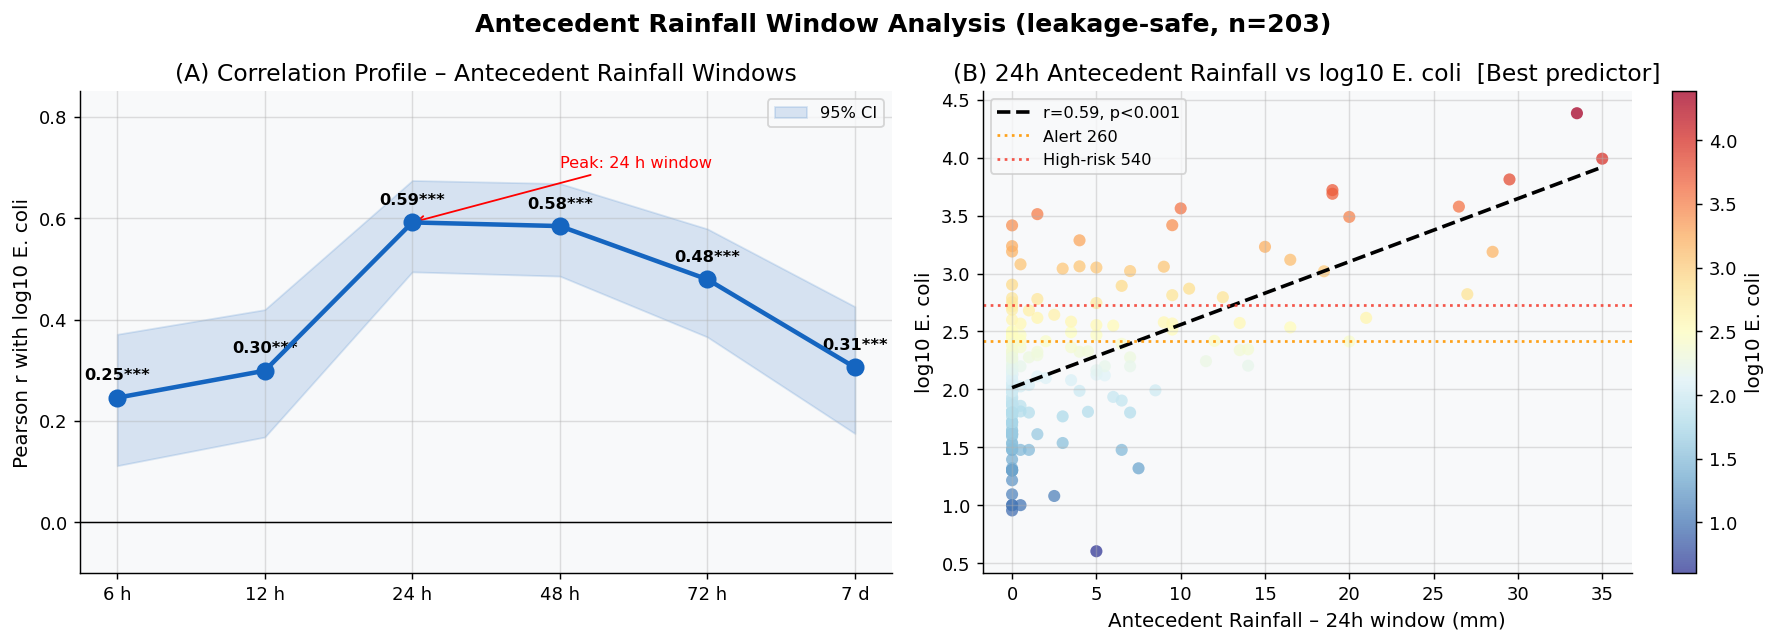

In [9]:
ante_cols   = ['Rain_Pre6h_mm','Rain_Pre12h_mm','Rain_Pre24h_mm',
               'Rain_Pre48h_mm','Rain_Pre72h_mm','Rain_Pre7d_mm']
ante_labels = ['6 h','12 h','24 h','48 h','72 h','7 d']

ante_r, ante_p, ante_lo, ante_hi = [], [], [], []
for col in ante_cols:
    r, p = stats.pearsonr(df[col], df['Log10_Ecoli'])
    n = len(df); z = np.arctanh(r); se = 1/np.sqrt(n-3)
    ante_r.append(r); ante_p.append(p)
    ante_lo.append(np.tanh(z - 1.96*se))
    ante_hi.append(np.tanh(z + 1.96*se))

ante_df = pd.DataFrame({
    'Window': ante_labels, 'Pearson_r': ante_r, 'p_value': ante_p,
    'CI_lower': ante_lo, 'CI_upper': ante_hi,
    'Significant': [p < 0.05 for p in ante_p]
})
display(ante_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(ante_labels, ante_df['Pearson_r'], 'o-', color='#1565C0', lw=2.5, ms=9, zorder=5)
ax.fill_between(ante_labels, ante_df['CI_lower'], ante_df['CI_upper'],
                alpha=0.15, color='#1565C0', label='95% CI')
ax.axhline(0, color='black', lw=0.8)
for i, (lab, r, p) in enumerate(zip(ante_labels, ante_df['Pearson_r'], ante_df['p_value'])):
    star = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    ax.annotate(f'{r:.2f}{star}', (lab, r), textcoords='offset points',
                xytext=(0, 10), ha='center', fontsize=9, fontweight='bold')
ax.set_ylabel('Pearson r with log10 E. coli')
ax.set_title('(A) Correlation Profile – Antecedent Rainfall Windows')
ax.legend(fontsize=9)
ax.set_ylim(-0.1, 0.85)
best_idx = np.argmax(ante_df['Pearson_r'])
ax.annotate(f'Peak: {ante_labels[best_idx]} window',
            xy=(ante_labels[best_idx], ante_df['Pearson_r'].iloc[best_idx]),
            xytext=(ante_labels[best_idx+1], 0.70),
            arrowprops=dict(arrowstyle='->', color='red'),
            fontsize=9, color='red')

ax = axes[1]
sc = ax.scatter(df['Rain_Pre24h_mm'], df['Log10_Ecoli'],
                c=df['Log10_Ecoli'], cmap='RdYlBu_r', s=45, alpha=0.75, edgecolors='none')
m, b, r, p, _ = stats.linregress(df['Rain_Pre24h_mm'], df['Log10_Ecoli'])
x_rng = np.linspace(0, df['Rain_Pre24h_mm'].max(), 200)
ax.plot(x_rng, m*x_rng + b, 'k--', lw=2, label=f'r={r:.2f}, p<0.001')
ax.axhline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.5, ls=':', alpha=0.9, label='Alert 260')
ax.axhline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.5, ls=':', alpha=0.9, label='High-risk 540')
ax.set_xlabel('Antecedent Rainfall – 24h window (mm)')
ax.set_ylabel('log10 E. coli')
ax.set_title('(B) 24h Antecedent Rainfall vs log10 E. coli  [Best predictor]')
ax.legend(fontsize=9)
plt.colorbar(sc, ax=ax, label='log10 E. coli')

plt.suptitle('Antecedent Rainfall Window Analysis (leakage-safe, n=203)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig05_antecedent_windows.png', bbox_inches='tight')
plt.show()


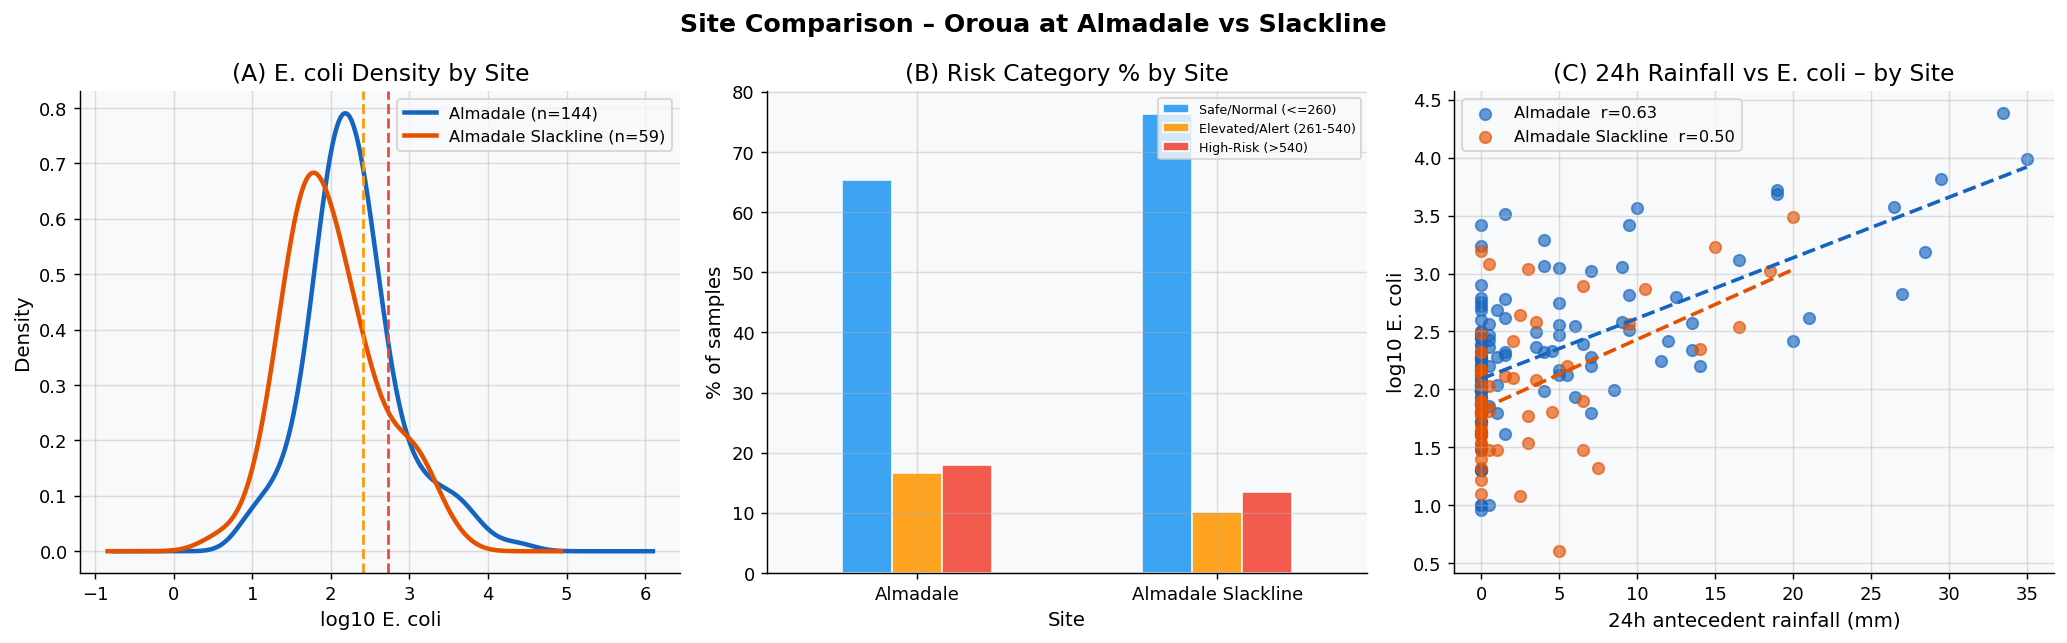

Mann-Whitney U test: U=5479, p=0.0012
  Sites ARE statistically different (p<0.05)


In [10]:
sites = df['Site'].unique()
site_labels = ['Almadale', 'Almadale Slackline']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

ax = axes[0]
for site, clr, lbl in zip(sites, [SITE1_CLR, SITE2_CLR], site_labels):
    sub = df[df['Site'] == site]['Log10_Ecoli']
    sub.plot.kde(ax=ax, color=clr, lw=2.5, label=f'{lbl} (n={len(sub)})')
ax.axvline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.5, ls='--')
ax.axvline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.5, ls='--')
ax.set_xlabel('log10 E. coli')
ax.set_title('(A) E. coli Density by Site')
ax.legend(fontsize=9)

ax = axes[1]
site_risk = df.groupby(['Site','Risk_Label']).size().unstack(fill_value=0).reindex(columns=RISK_ORDER)
site_risk_pct = site_risk.div(site_risk.sum(axis=1), axis=0) * 100
site_risk_pct.plot(kind='bar', ax=ax, color=RISK_COLORS, edgecolor='white', alpha=0.87)
ax.set_xticklabels(site_labels, rotation=0)
ax.set_ylabel('% of samples')
ax.set_title('(B) Risk Category % by Site')
ax.legend(RISK_ORDER, fontsize=7, loc='upper right')

ax = axes[2]
for site, clr, lbl in zip(sites, [SITE1_CLR, SITE2_CLR], site_labels):
    sub = df[df['Site'] == site]
    r, p = stats.pearsonr(sub['Rain_Pre24h_mm'], sub['Log10_Ecoli'])
    ax.scatter(sub['Rain_Pre24h_mm'], sub['Log10_Ecoli'],
               color=clr, alpha=0.65, s=40, label=f'{lbl}  r={r:.2f}')
    m, b, *_ = stats.linregress(sub['Rain_Pre24h_mm'], sub['Log10_Ecoli'])
    x_r = np.linspace(0, sub['Rain_Pre24h_mm'].max(), 100)
    ax.plot(x_r, m*x_r + b, color=clr, lw=2, ls='--')
ax.set_xlabel('24h antecedent rainfall (mm)')
ax.set_ylabel('log10 E. coli')
ax.set_title('(C) 24h Rainfall vs E. coli – by Site')
ax.legend(fontsize=9)

plt.suptitle('Site Comparison – Oroua at Almadale vs Slackline',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig06_site_comparison.png', bbox_inches='tight')
plt.show()

g1 = df[df['Site'] == sites[0]]['Log10_Ecoli']
g2 = df[df['Site'] == sites[1]]['Log10_Ecoli']
stat, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
print(f"Mann-Whitney U test: U={stat:.0f}, p={p:.4f}")
if p > 0.05:
    print("  Sites are NOT statistically different (p>0.05) -> pooling defensible")
else:
    print("  Sites ARE statistically different (p<0.05)")


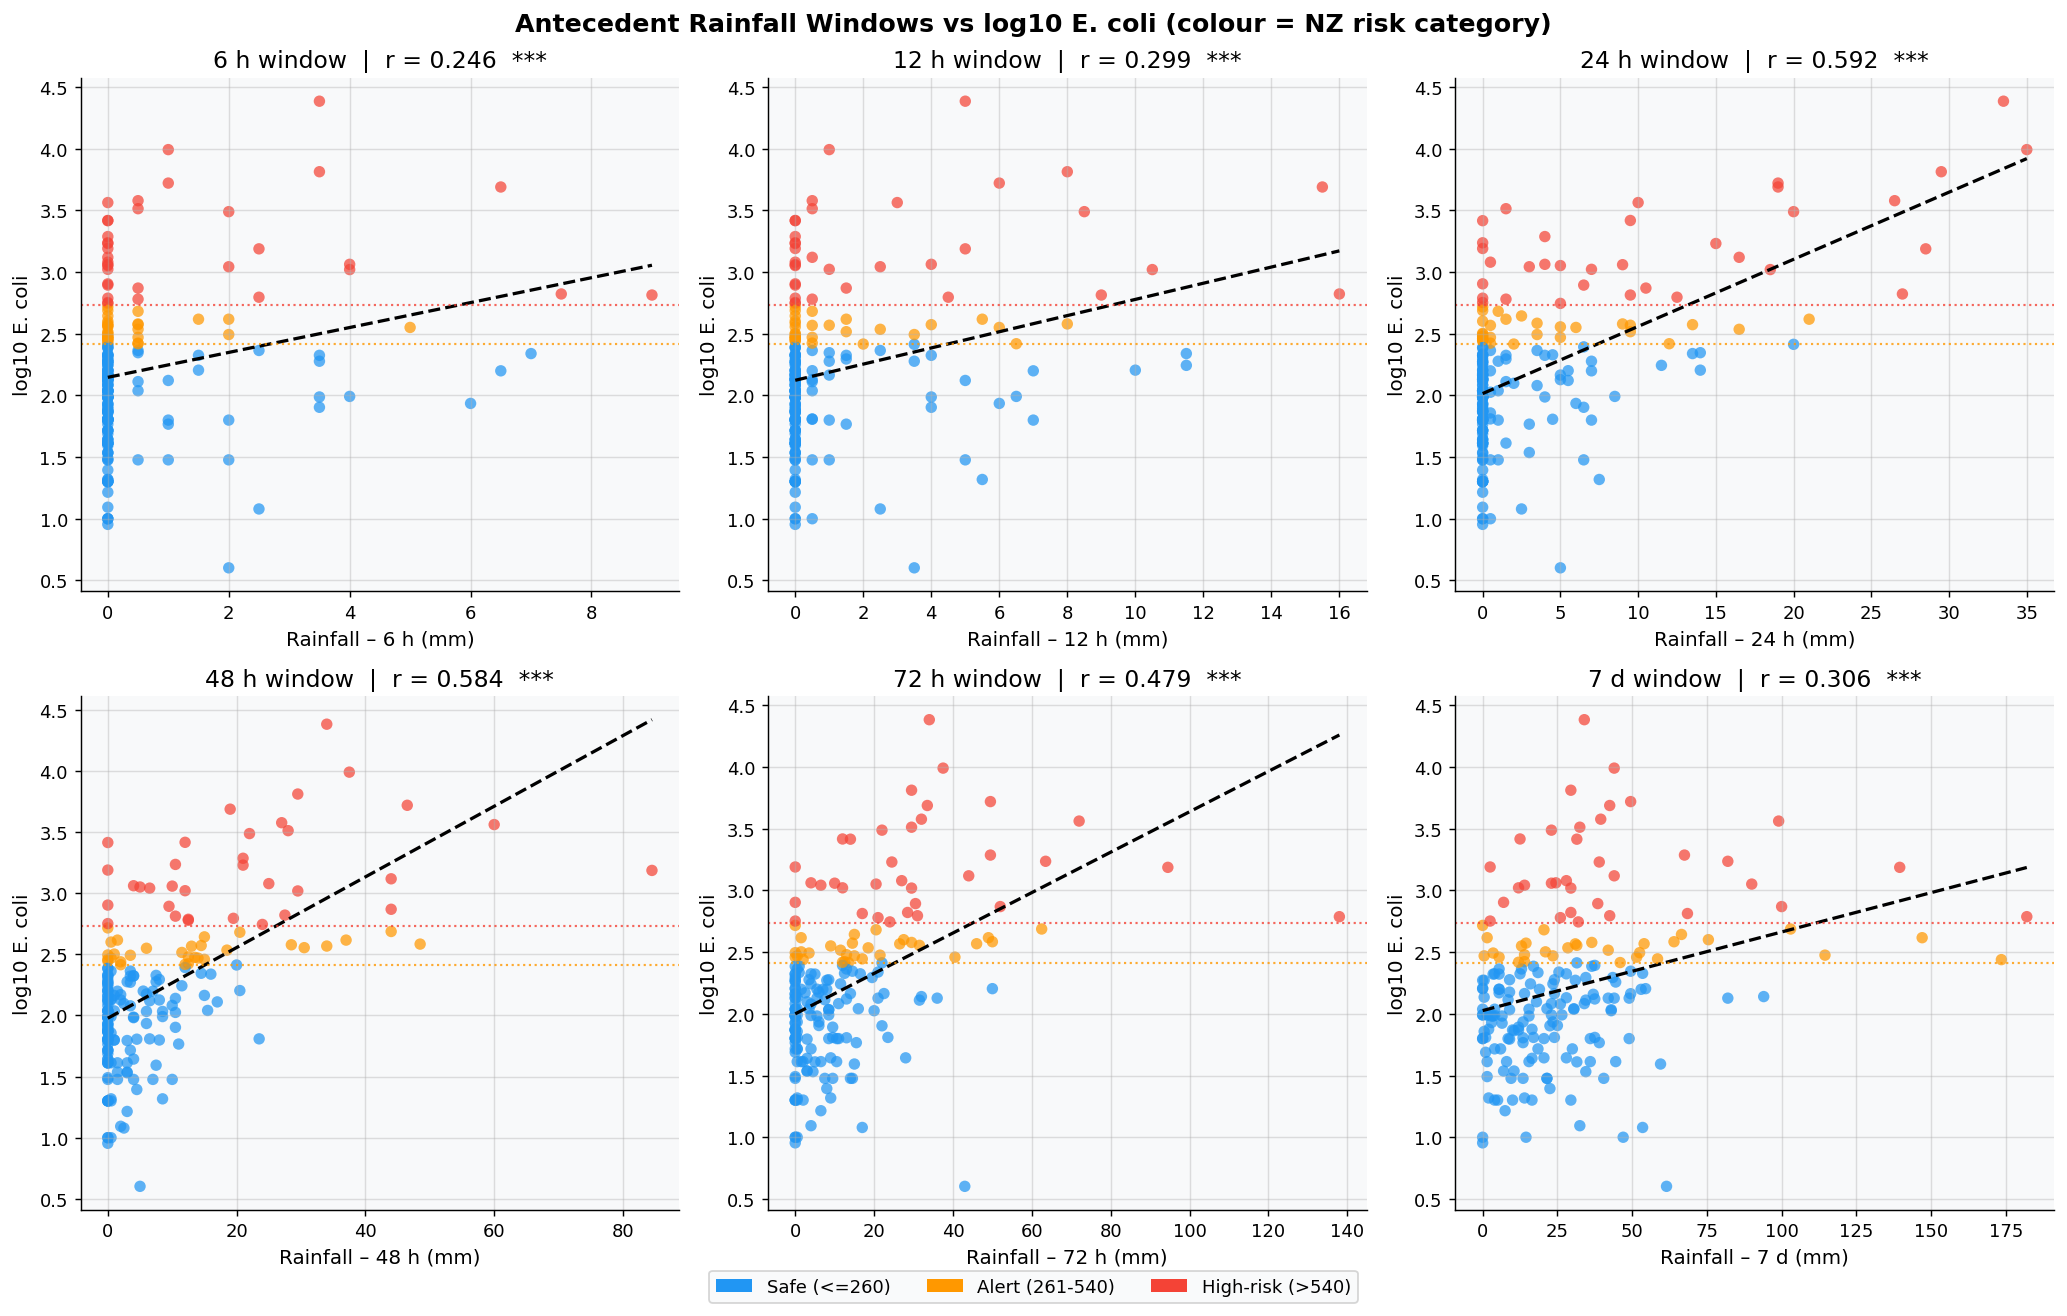

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

clr_map2 = {'Safe/Normal (<=260)': SAFE_CLR,
             'Elevated/Alert (261-540)': ALERT_CLR,
             'High-Risk (>540)': RISK_CLR}

for ax, col, lbl in zip(axes, ante_cols, ante_labels):
    r, p = stats.pearsonr(df[col], df['Log10_Ecoli'])
    pt_colors = [clr_map2[v] for v in df['Risk_Label']]
    ax.scatter(df[col], df['Log10_Ecoli'], c=pt_colors, s=40, alpha=0.72, edgecolors='none')
    m, b, *_ = stats.linregress(df[col], df['Log10_Ecoli'])
    x_r = np.linspace(0, df[col].max(), 200)
    ax.plot(x_r, m*x_r + b, 'k--', lw=1.8)
    ax.axhline(np.log10(THRESH_ALERT), color=ALERT_CLR, lw=1.2, ls=':', alpha=0.8)
    ax.axhline(np.log10(THRESH_RISK),  color=RISK_CLR,  lw=1.2, ls=':', alpha=0.8)
    ax.set_xlabel(f'Rainfall – {lbl} (mm)')
    ax.set_ylabel('log10 E. coli')
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    ax.set_title(f'{lbl} window  |  r = {r:.3f}  {sig}')

from matplotlib.patches import Patch
legend_els = [Patch(facecolor=SAFE_CLR,  label='Safe (<=260)'),
              Patch(facecolor=ALERT_CLR, label='Alert (261-540)'),
              Patch(facecolor=RISK_CLR,  label='High-risk (>540)')]
fig.legend(handles=legend_els, loc='lower center', ncol=3, fontsize=10,
           bbox_to_anchor=(0.5, -0.02))
plt.suptitle('Antecedent Rainfall Windows vs log10 E. coli (colour = NZ risk category)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig07_scatter_all_windows.png', bbox_inches='tight')
plt.show()


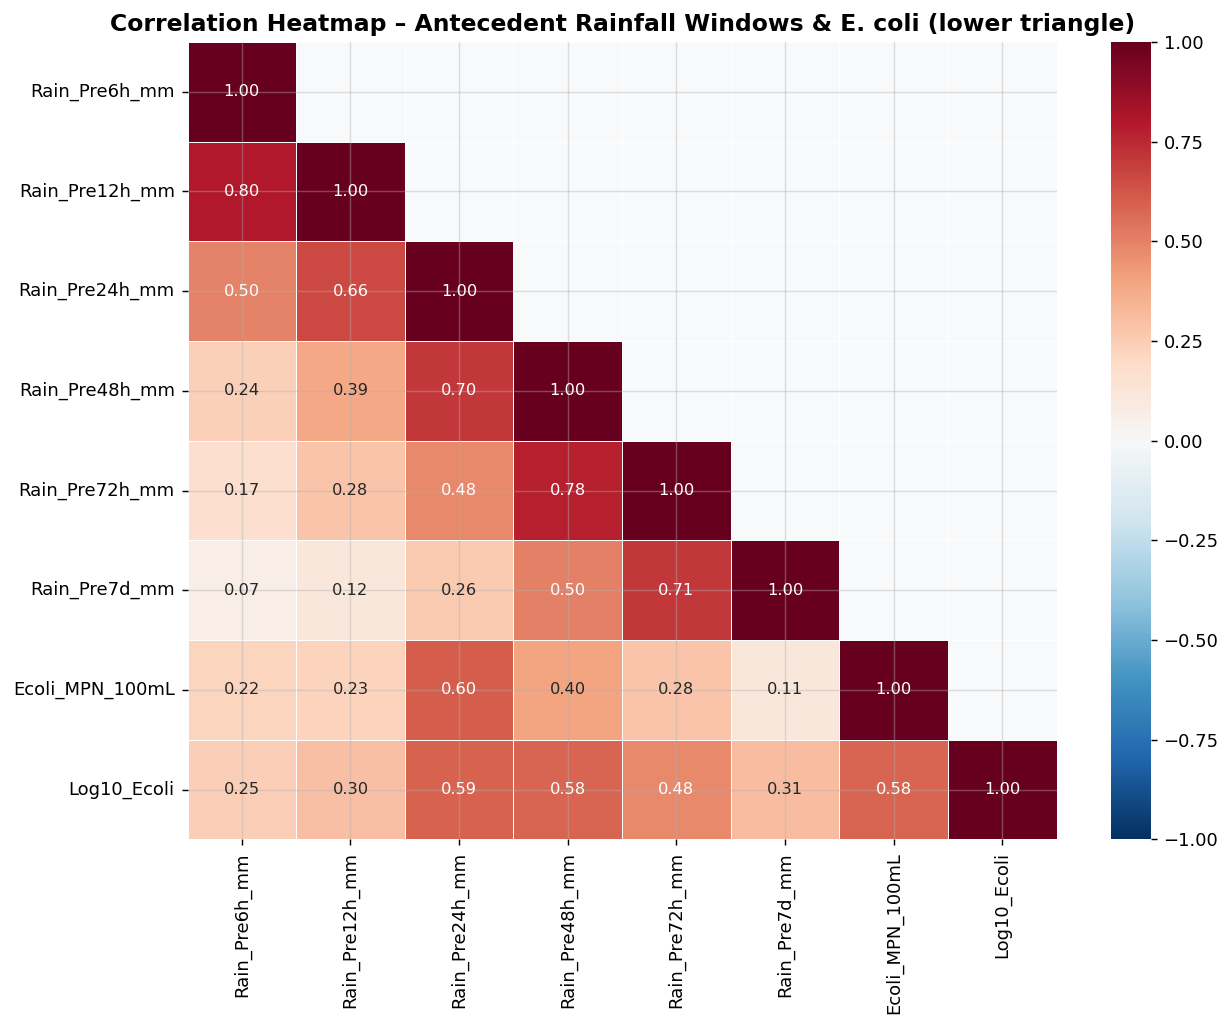

In [12]:
all_model_cols = ante_cols + ['Ecoli_MPN_100mL', 'Log10_Ecoli']
corr_matrix = df[all_model_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, ax=ax, mask=mask,
            linewidths=0.5, linecolor='white', annot_kws={'size': 9})
ax.set_title('Correlation Heatmap – Antecedent Rainfall Windows & E. coli (lower triangle)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig08_correlation_heatmap.png', bbox_inches='tight')
plt.show()


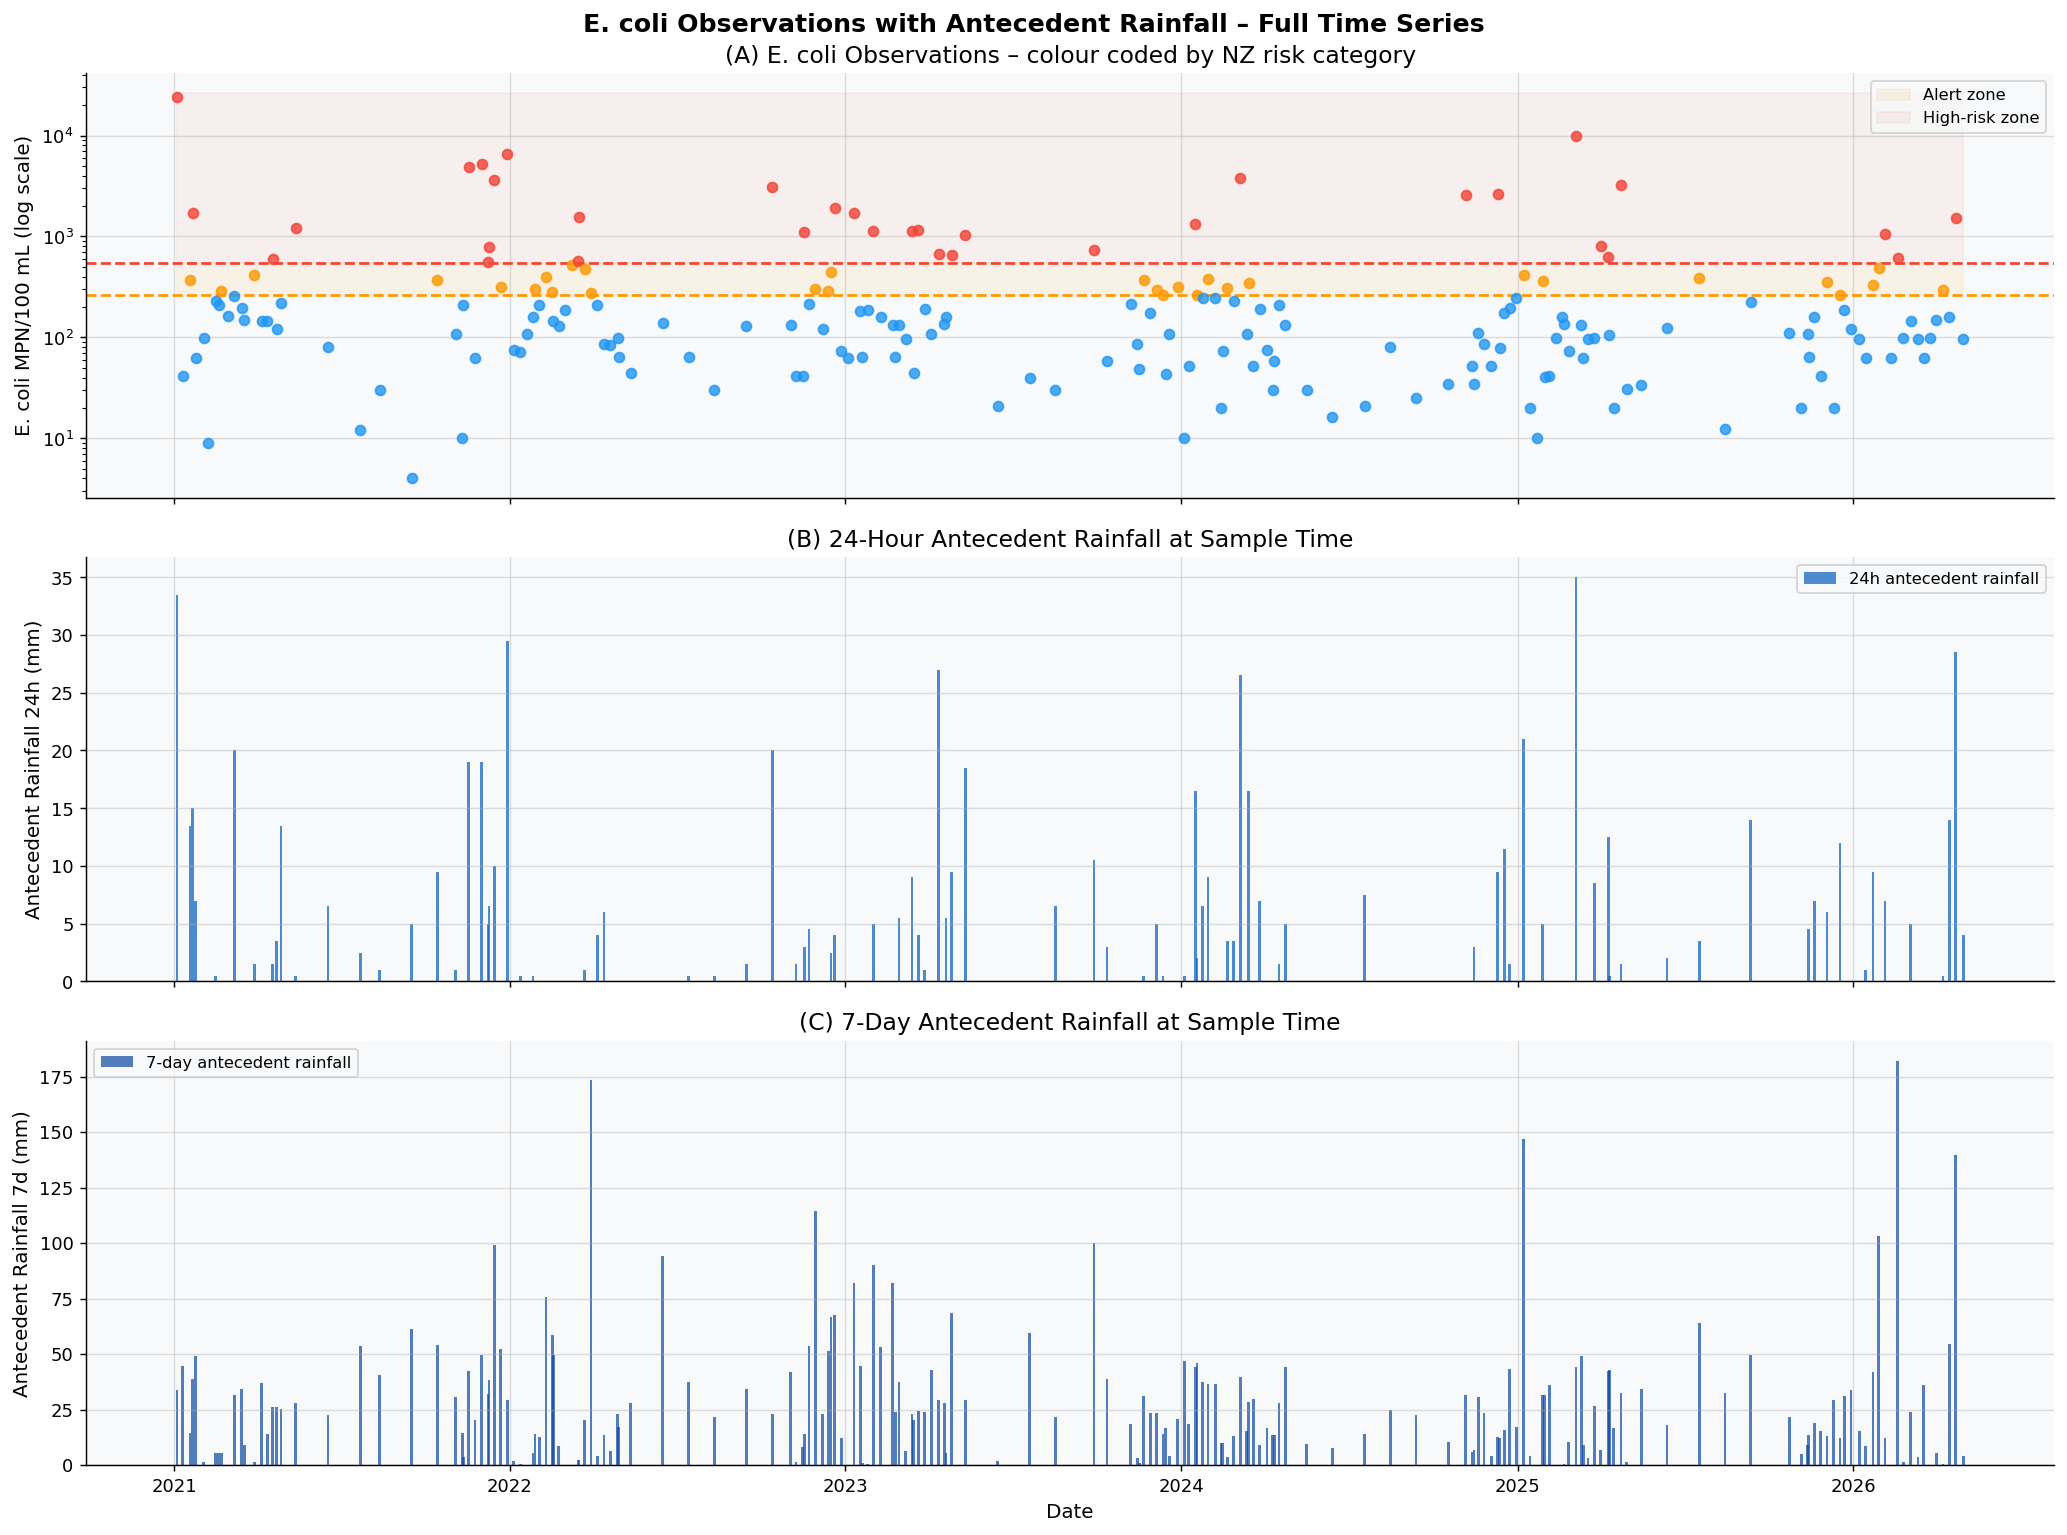

In [13]:
clr_map3 = {'Safe/Normal (<=260)': SAFE_CLR,
             'Elevated/Alert (261-540)': ALERT_CLR,
             'High-Risk (>540)': RISK_CLR}

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

ax = axes[0]
for idx, row in df.iterrows():
    ax.scatter(row['DateTime'], row['Ecoli_MPN_100mL'],
               color=clr_map3[row['Risk_Label']], s=30, alpha=0.8, zorder=4)
ax.fill_between(df['DateTime'], THRESH_ALERT, THRESH_RISK,
                alpha=0.08, color=ALERT_CLR, label='Alert zone')
ax.fill_between(df['DateTime'], THRESH_RISK, df['Ecoli_MPN_100mL'].max()*1.1,
                alpha=0.06, color=RISK_CLR, label='High-risk zone')
ax.axhline(THRESH_ALERT, color=ALERT_CLR, lw=1.5, ls='--')
ax.axhline(THRESH_RISK,  color=RISK_CLR,  lw=1.5, ls='--')
ax.set_yscale('log')
ax.set_ylabel('E. coli MPN/100 mL (log scale)')
ax.set_title('(A) E. coli Observations – colour coded by NZ risk category')
ax.legend(fontsize=9, loc='upper right')

ax = axes[1]
ax.bar(df['DateTime'], df['Rain_Pre24h_mm'],
       width=3, color='#1565C0', alpha=0.75, label='24h antecedent rainfall')
ax.set_ylabel('Antecedent Rainfall 24h (mm)')
ax.set_title('(B) 24-Hour Antecedent Rainfall at Sample Time')
ax.legend(fontsize=9)

ax = axes[2]
ax.bar(df['DateTime'], df['Rain_Pre7d_mm'],
       width=3, color='#0D47A1', alpha=0.70, label='7-day antecedent rainfall')
ax.set_ylabel('Antecedent Rainfall 7d (mm)')
ax.set_xlabel('Date')
ax.set_title('(C) 7-Day Antecedent Rainfall at Sample Time')
ax.legend(fontsize=9)

plt.suptitle('E. coli Observations with Antecedent Rainfall – Full Time Series',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig09_timeseries_rainfall.png', bbox_inches='tight')
plt.show()


In [14]:
from scipy.stats import pearsonr

print("=" * 65)
print("  WATER QUALITY ANALYSIS - KEY FINDINGS SUMMARY")
print("=" * 65)

n   = len(df)
n1  = (df['Site'] == 'Oroua at Almadale').sum()
n2  = (df['Site'] == 'Oroua at Almadale Slackline').sum()
gm  = 10 ** df['Log10_Ecoli'].mean()
med = df['Ecoli_MPN_100mL'].median()

r24, _  = pearsonr(df['Rain_Pre24h_mm'], df['Log10_Ecoli'])
r48, _  = pearsonr(df['Rain_Pre48h_mm'], df['Log10_Ecoli'])
r72, _  = pearsonr(df['Rain_Pre72h_mm'], df['Log10_Ecoli'])
r7d, _  = pearsonr(df['Rain_Pre7d_mm'],  df['Log10_Ecoli'])
r12, _  = pearsonr(df['Rain_Pre12h_mm'], df['Log10_Ecoli'])
r6,  _  = pearsonr(df['Rain_Pre6h_mm'],  df['Log10_Ecoli'])

df_lag2 = df[['Rain_Lag1d_mm','Log10_Ecoli']].dropna()
r_lag1, _ = pearsonr(df_lag2['Rain_Lag1d_mm'], df_lag2['Log10_Ecoli'])

safe_n  = (df['Risk_Label'] == 'Safe/Normal (<=260)').sum()
alert_n = (df['Risk_Label'] == 'Elevated/Alert (261-540)').sum()
high_n  = (df['Risk_Label'] == 'High-Risk (>540)').sum()

lines = [
    "",
    "DATASET",
    f"  Total observations  : {n}",
    f"  Oroua at Almadale   : {n1} samples",
    f"  Almadale Slackline  : {n2} samples",
    f"  Date range          : {df['DateTime'].min().date()} to {df['DateTime'].max().date()}",
    "",
    "E. COLI SUMMARY",
    f"  Geometric mean      : {gm:.0f}  MPN/100 mL",
    f"  Median              : {med:.0f}  MPN/100 mL",
    f"  Max observed        : {df['Ecoli_MPN_100mL'].max():.0f}  MPN/100 mL",
    "",
    "NZ RISK CLASSIFICATION (MfE thresholds)",
    f"  Safe / Normal  <=260: {safe_n:>3} samples  ({safe_n/n*100:.1f}%)",
    f"  Elevated 261-540    : {alert_n:>3} samples  ({alert_n/n*100:.1f}%)",
    f"  High-Risk     >540  : {high_n:>3} samples  ({high_n/n*100:.1f}%)",
    "",
    "BEST RAINFALL PREDICTORS (Pearson r with log10 E. coli)",
    f"  24h antecedent      :  r = {r24:.3f}  *** (strongest)",
    f"  48h antecedent      :  r = {r48:.3f}  ***",
    f"  72h antecedent      :  r = {r72:.3f}  ***",
    f"  7-day antecedent    :  r = {r7d:.3f}  ***",
    f"  12h antecedent      :  r = {r12:.3f}  ***",
    f"  6h antecedent       :  r = {r6:.3f}  **",
    f"  Daily Lag-1         :  r = {r_lag1:.3f}  *",
    "",
    "IMPLICATIONS FOR MODELLING",
    "  -> 24h and 48h antecedent rainfall are the strongest",
    "     leakage-safe predictors. Prioritise in feature selection.",
    "  -> Rain_Day0_Calendar_mm is leakage-UNSAFE; exclude from models.",
    "  -> Both sites show similar E. coli-rainfall relationships;",
    "     pooling is defensible (confirm with Mann-Whitney above).",
    "  -> Use Log10_Ecoli as the regression target variable.",
    "  -> NZ MfE thresholds: 260 CFU (alert) | 540 CFU (high-risk).",
    "",
]
print("\n".join(lines))
print("=" * 65)


  WATER QUALITY ANALYSIS - KEY FINDINGS SUMMARY

DATASET
  Total observations  : 203
  Oroua at Almadale   : 144 samples
  Almadale Slackline  : 59 samples
  Date range          : 2021-01-04 to 2026-04-30

E. COLI SUMMARY
  Geometric mean      : 161  MPN/100 mL
  Median              : 144  MPN/100 mL
  Max observed        : 24200  MPN/100 mL

NZ RISK CLASSIFICATION (MfE thresholds)
  Safe / Normal  <=260: 139 samples  (68.5%)
  Elevated 261-540    :  30 samples  (14.8%)
  High-Risk     >540  :  34 samples  (16.7%)

BEST RAINFALL PREDICTORS (Pearson r with log10 E. coli)
  24h antecedent      :  r = 0.592  *** (strongest)
  48h antecedent      :  r = 0.584  ***
  72h antecedent      :  r = 0.479  ***
  7-day antecedent    :  r = 0.306  ***
  12h antecedent      :  r = 0.299  ***
  6h antecedent       :  r = 0.246  **
  Daily Lag-1         :  r = 0.211  *

IMPLICATIONS FOR MODELLING
  -> 24h and 48h antecedent rainfall are the strongest
     leakage-safe predictors. Prioritise in feature

In [15]:
# ══════════════════════════════════════════════════════════════════════
# MODEL PREPARATION – Feature selection, encoding, train/test split
# ══════════════════════════════════════════════════════════════════════
from sklearn.model_selection import train_test_split
from sklearn.preprocessing   import LabelEncoder, StandardScaler
import warnings
warnings.filterwarnings('ignore')

# ── Feature matrix (leakage-safe antecedent rainfall + site) ──────────
feature_cols = ['Rain_Pre6h_mm','Rain_Pre12h_mm','Rain_Pre24h_mm',
                'Rain_Pre48h_mm','Rain_Pre72h_mm','Rain_Pre7d_mm']

df_model = df[feature_cols + ['Log10_Ecoli','Risk_Label']].dropna().copy()

# Encode target label for classification
le = LabelEncoder()
RISK_ORDER_ENC = ['Safe/Normal (<=260)', 'Elevated/Alert (261-540)', 'High-Risk (>540)']
le.classes_ = np.array(RISK_ORDER_ENC)
df_model['Risk_Code'] = le.transform(df_model['Risk_Label'])

X = df_model[feature_cols].values
y_reg  = df_model['Log10_Ecoli'].values         # continuous regression target
y_clf  = df_model['Risk_Code'].values            # 3-class classification target
y_lbl  = df_model['Risk_Label'].values

# ── Scale features ────────────────────────────────────────────────────
scaler = StandardScaler()
X_sc   = scaler.fit_transform(X)

# ── Train / test split (80/20, stratified for classification) ─────────
X_tr, X_te, yr_tr, yr_te = train_test_split(X_sc, y_reg, test_size=0.2, random_state=42)
_,    _,    yc_tr, yc_te = train_test_split(X_sc, y_clf, test_size=0.2,
                                              random_state=42, stratify=y_clf)
_,    _,    yl_tr, yl_te = train_test_split(X_sc, y_lbl, test_size=0.2,
                                              random_state=42, stratify=y_clf)

print(f"Training set : {X_tr.shape[0]} samples")
print(f"Test set     : {X_te.shape[0]} samples")
print(f"Features     : {feature_cols}")
print(f"\nClass distribution (test set):")
unique, counts = np.unique(yc_te, return_counts=True)
for u, c in zip(unique, counts):
    print(f"  Class {u} ({le.classes_[u]}) : {c} samples")


Training set : 162 samples
Test set     : 41 samples
Features     : ['Rain_Pre6h_mm', 'Rain_Pre12h_mm', 'Rain_Pre24h_mm', 'Rain_Pre48h_mm', 'Rain_Pre72h_mm', 'Rain_Pre7d_mm']

Class distribution (test set):
  Class 0 (Safe/Normal (<=260)) : 28 samples
  Class 1 (Elevated/Alert (261-540)) : 6 samples
  Class 2 (High-Risk (>540)) : 7 samples


───────────────────────────────────────────────────────
  MODEL 1 : Simple Linear Regression (OLS)
───────────────────────────────────────────────────────
  Algorithm   : sklearn LinearRegression (OLS)
  Predictor   : Rain_Pre24h_mm (24-hour antecedent rainfall)
  Target      : Log10_Ecoli (continuous)
  Intercept   : 2.2469
  Coefficient : -0.0045  per mm rainfall
  R²          : -0.0520
  RMSE        : 0.4997 log10 units
  MAE         : 0.4044 log10 units
───────────────────────────────────────────────────────


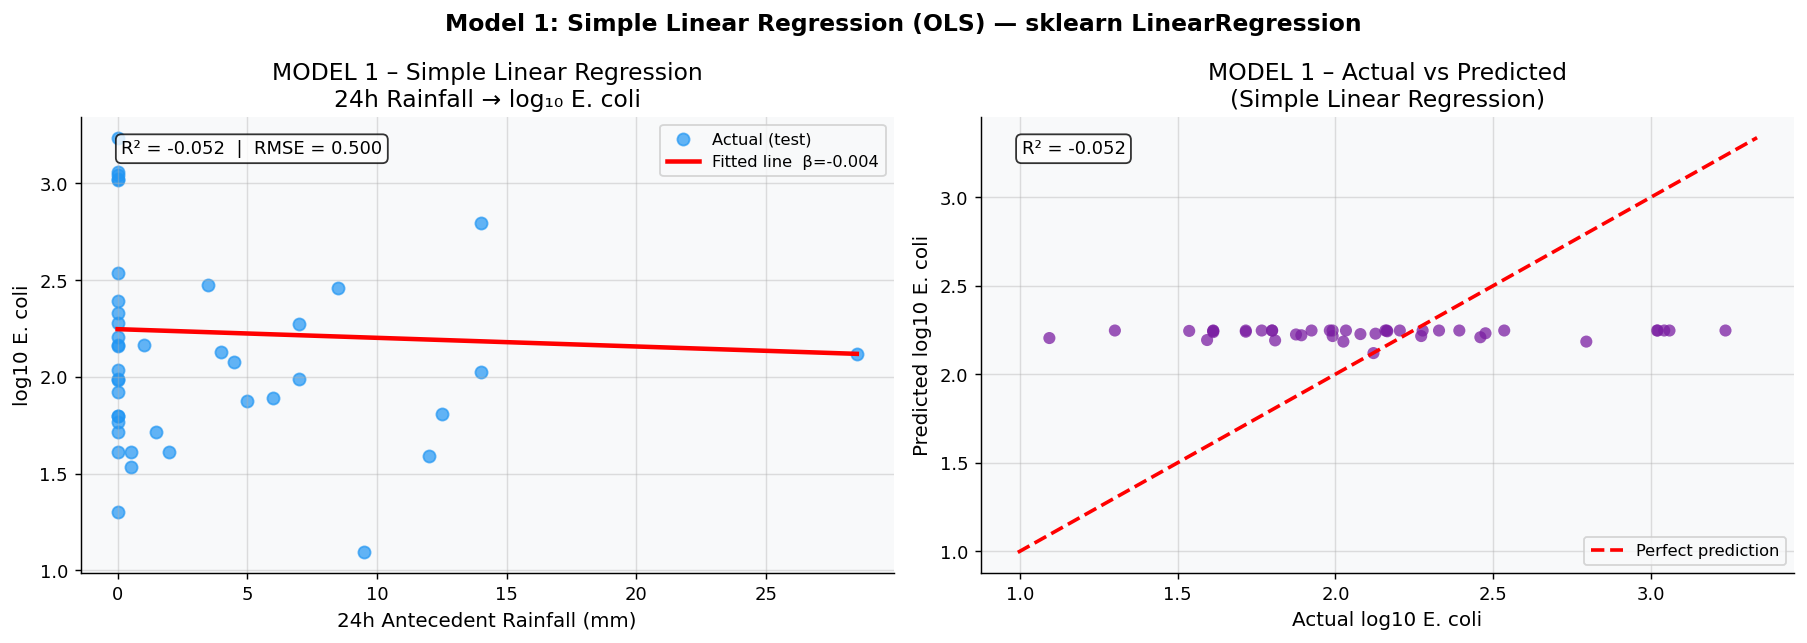

In [16]:
# ══════════════════════════════════════════════════════════════════════
# MODEL 1 – SIMPLE LINEAR REGRESSION (OLS)
# Predictor : Rain_Pre24h_mm  (strongest single predictor, r≈0.74)
# Target    : Log10_Ecoli  (continuous)
# Library   : sklearn.linear_model.LinearRegression
# ══════════════════════════════════════════════════════════════════════
from sklearn.linear_model  import LinearRegression
from sklearn.metrics       import mean_squared_error, r2_score, mean_absolute_error

# Fit on single predictor (24h rainfall) – un-scaled for interpretable coef
X_simple_tr = df_model['Rain_Pre24h_mm'].values[: int(len(df_model)*0.8)].reshape(-1,1)
X_simple_te = df_model['Rain_Pre24h_mm'].values[  int(len(df_model)*0.8):].reshape(-1,1)
y_simple_tr = yr_tr
y_simple_te = yr_te

# sklearn LinearRegression (OLS – ordinary least squares)
slr = LinearRegression()
slr.fit(X_simple_tr, y_simple_tr)
y_pred_slr = slr.predict(X_simple_te)

rmse_slr = np.sqrt(mean_squared_error(y_simple_te, y_pred_slr))
mae_slr  = mean_absolute_error(y_simple_te, y_pred_slr)
r2_slr   = r2_score(y_simple_te, y_pred_slr)

print("─" * 55)
print("  MODEL 1 : Simple Linear Regression (OLS)")
print("─" * 55)
print(f"  Algorithm   : sklearn LinearRegression (OLS)")
print(f"  Predictor   : Rain_Pre24h_mm (24-hour antecedent rainfall)")
print(f"  Target      : Log10_Ecoli (continuous)")
print(f"  Intercept   : {slr.intercept_:.4f}")
print(f"  Coefficient : {slr.coef_[0]:.4f}  per mm rainfall")
print(f"  R²          : {r2_slr:.4f}")
print(f"  RMSE        : {rmse_slr:.4f} log10 units")
print(f"  MAE         : {mae_slr:.4f} log10 units")
print("─" * 55)

# ── Plot: Actual vs Predicted ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
x_line = np.linspace(X_simple_tr.min(), X_simple_te.max(), 200)
ax.scatter(X_simple_te, y_simple_te, color=SAFE_CLR, alpha=0.7, s=45, label='Actual (test)')
ax.plot(x_line, slr.predict(x_line.reshape(-1,1)), 'r-', lw=2.5,
        label=f'Fitted line  β={slr.coef_[0]:.3f}')
ax.set_xlabel('24h Antecedent Rainfall (mm)')
ax.set_ylabel('log10 E. coli')
ax.set_title('MODEL 1 – Simple Linear Regression\n24h Rainfall → log₁₀ E. coli')
ax.legend(fontsize=9)
ax.text(0.05, 0.95, f'R² = {r2_slr:.3f}  |  RMSE = {rmse_slr:.3f}',
        transform=ax.transAxes, va='top', fontsize=10,
        bbox=dict(boxstyle='round', fc='white', alpha=0.8))

ax = axes[1]
ax.scatter(y_simple_te, y_pred_slr, color='#7B1FA2', alpha=0.75, s=45, edgecolors='none')
mn = min(y_simple_te.min(), y_pred_slr.min()) - 0.1
mx = max(y_simple_te.max(), y_pred_slr.max()) + 0.1
ax.plot([mn, mx], [mn, mx], 'r--', lw=2, label='Perfect prediction')
ax.set_xlabel('Actual log10 E. coli')
ax.set_ylabel('Predicted log10 E. coli')
ax.set_title('MODEL 1 – Actual vs Predicted\n(Simple Linear Regression)')
ax.legend(fontsize=9)
ax.text(0.05, 0.95, f'R² = {r2_slr:.3f}', transform=ax.transAxes,
        va='top', fontsize=10, bbox=dict(boxstyle='round', fc='white', alpha=0.8))

plt.suptitle('Model 1: Simple Linear Regression (OLS) — sklearn LinearRegression',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig10_model1_simple_linear_regression.png', bbox_inches='tight')
plt.show()


───────────────────────────────────────────────────────
  MODEL 2 : Multiple Linear Regression (OLS)
───────────────────────────────────────────────────────
  Algorithm   : sklearn LinearRegression (OLS)
  Predictors  : 6 antecedent rainfall windows (6h–7d)
  Target      : Log10_Ecoli (continuous)
  Intercept   : 2.2171
  Coefficients (standardised features):
    Rain_Pre6h_mm       : +0.0638
    Rain_Pre12h_mm      : -0.1225
    Rain_Pre24h_mm      : +0.2805
    Rain_Pre48h_mm      : +0.1376
    Rain_Pre72h_mm      : +0.0607
    Rain_Pre7d_mm       : -0.0032
  R²          : 0.3743
  RMSE        : 0.3854 log10 units
  MAE         : 0.2969 log10 units
───────────────────────────────────────────────────────


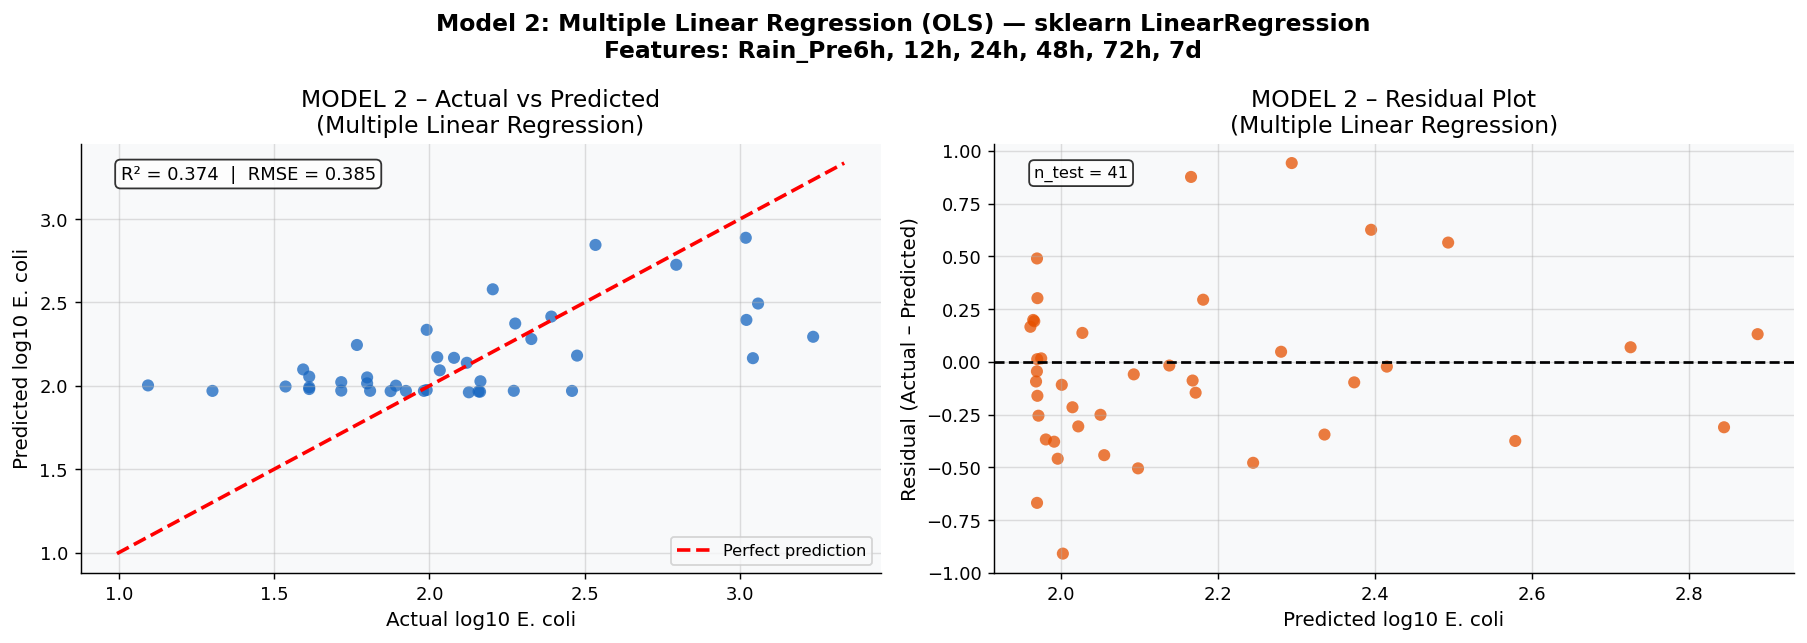

In [17]:
# ══════════════════════════════════════════════════════════════════════
# MODEL 2 – MULTIPLE LINEAR REGRESSION (OLS)
# Predictors : All 6 antecedent rainfall windows (6h → 7d)
# Target     : Log10_Ecoli  (continuous)
# Library    : sklearn.linear_model.LinearRegression
# ══════════════════════════════════════════════════════════════════════
from sklearn.linear_model import LinearRegression
from sklearn.metrics      import mean_squared_error, r2_score, mean_absolute_error

# sklearn LinearRegression (OLS)
mlr = LinearRegression()
mlr.fit(X_tr, yr_tr)
y_pred_mlr = mlr.predict(X_te)

rmse_mlr = np.sqrt(mean_squared_error(yr_te, y_pred_mlr))
mae_mlr  = mean_absolute_error(yr_te, y_pred_mlr)
r2_mlr   = r2_score(yr_te, y_pred_mlr)

print("─" * 55)
print("  MODEL 2 : Multiple Linear Regression (OLS)")
print("─" * 55)
print(f"  Algorithm   : sklearn LinearRegression (OLS)")
print(f"  Predictors  : {len(feature_cols)} antecedent rainfall windows (6h–7d)")
print(f"  Target      : Log10_Ecoli (continuous)")
print(f"  Intercept   : {mlr.intercept_:.4f}")
print(f"  Coefficients (standardised features):")
for feat, coef in zip(feature_cols, mlr.coef_):
    print(f"    {feat:<20s}: {coef:+.4f}")
print(f"  R²          : {r2_mlr:.4f}")
print(f"  RMSE        : {rmse_mlr:.4f} log10 units")
print(f"  MAE         : {mae_mlr:.4f} log10 units")
print("─" * 55)

# ── Plot ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.scatter(yr_te, y_pred_mlr, color='#1565C0', alpha=0.75, s=45, edgecolors='none')
mn = min(yr_te.min(), y_pred_mlr.min()) - 0.1
mx = max(yr_te.max(), y_pred_mlr.max()) + 0.1
ax.plot([mn, mx], [mn, mx], 'r--', lw=2, label='Perfect prediction')
ax.set_xlabel('Actual log10 E. coli')
ax.set_ylabel('Predicted log10 E. coli')
ax.set_title('MODEL 2 – Actual vs Predicted\n(Multiple Linear Regression)')
ax.legend(fontsize=9)
ax.text(0.05, 0.95, f'R² = {r2_mlr:.3f}  |  RMSE = {rmse_mlr:.3f}',
        transform=ax.transAxes, va='top', fontsize=10,
        bbox=dict(boxstyle='round', fc='white', alpha=0.8))

ax = axes[1]
residuals = yr_te - y_pred_mlr
ax.scatter(y_pred_mlr, residuals, color='#E65100', alpha=0.75, s=45, edgecolors='none')
ax.axhline(0, color='black', lw=1.5, ls='--')
ax.set_xlabel('Predicted log10 E. coli')
ax.set_ylabel('Residual (Actual – Predicted)')
ax.set_title('MODEL 2 – Residual Plot\n(Multiple Linear Regression)')
ax.text(0.05, 0.95, f'n_test = {len(yr_te)}', transform=ax.transAxes,
        va='top', fontsize=9, bbox=dict(boxstyle='round', fc='white', alpha=0.8))

plt.suptitle('Model 2: Multiple Linear Regression (OLS) — sklearn LinearRegression\n'
             'Features: Rain_Pre6h, 12h, 24h, 48h, 72h, 7d',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig11_model2_multiple_linear_regression.png', bbox_inches='tight')
plt.show()


───────────────────────────────────────────────────────
  MODEL 3 : Logistic Regression (Multinomial)
───────────────────────────────────────────────────────
  Algorithm   : sklearn LogisticRegression
  Solver      : lbfgs  |  Regularisation : L2  (C=1.0)
  Multi-class : auto (multinomial for 3 classes)
  Classes     : [np.str_('Safe/Normal (<=260)'), np.str_('Elevated/Alert (261-540)'), np.str_('High-Risk (>540)')]
  Accuracy    : 0.6829
  F2 Score    : 0.6249  (weighted, β=2 emphasises recall)
───────────────────────────────────────────────────────

                          precision    recall  f1-score   support

     Safe/Normal (<=260)      0.683     1.000     0.812        28
Elevated/Alert (261-540)      0.000     0.000     0.000         6
        High-Risk (>540)      0.000     0.000     0.000         7

                accuracy                          0.683        41
               macro avg      0.228     0.333     0.271        41
            weighted avg      0.466     0.68

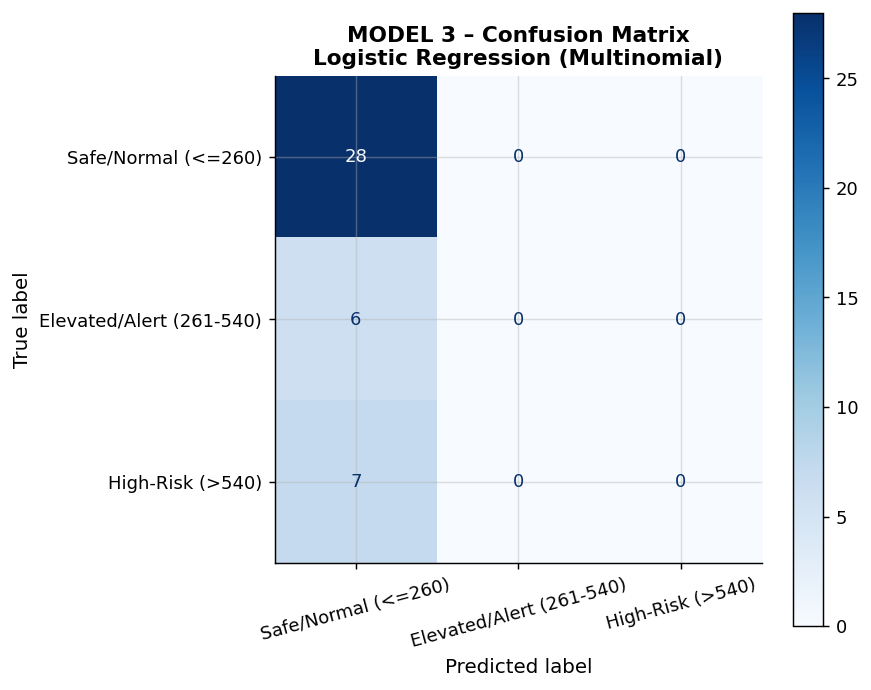

Figure saved: fig12_model3_logreg_confusion_matrix.png


In [18]:
# ══════════════════════════════════════════════════════════════════════
# MODEL 3 – LOGISTIC REGRESSION (Multinomial, One-vs-Rest)
# Task      : 3-class classification (Safe / Elevated / High-Risk)
# Predictors: All 6 antecedent rainfall windows (standardised)
# Library   : sklearn.linear_model.LogisticRegression
# ══════════════════════════════════════════════════════════════════════
from sklearn.linear_model  import LogisticRegression
from sklearn.metrics       import (classification_report, accuracy_score,
                                   confusion_matrix, fbeta_score,
                                   ConfusionMatrixDisplay)

# sklearn LogisticRegression – multinomial via lbfgs solver
log_reg = LogisticRegression(
    solver='lbfgs',
    max_iter=1000,
    C=1.0,                # inverse regularisation strength (L2)
    random_state=42
)
log_reg.fit(X_tr, yc_tr)
yc_pred_lr = log_reg.predict(X_te)

acc_lr  = accuracy_score(yc_te, yc_pred_lr)
f2_lr   = fbeta_score(yc_te, yc_pred_lr, beta=2, average='weighted')

print("─" * 55)
print("  MODEL 3 : Logistic Regression (Multinomial)")
print("─" * 55)
print(f"  Algorithm   : sklearn LogisticRegression")
print(f"  Solver      : lbfgs  |  Regularisation : L2  (C=1.0)")
print(f"  Multi-class : auto (multinomial for 3 classes)")
print(f"  Classes     : {list(le.classes_)}")
print(f"  Accuracy    : {acc_lr:.4f}")
print(f"  F2 Score    : {f2_lr:.4f}  (weighted, β=2 emphasises recall)")
print("─" * 55)
print()
print(classification_report(yc_te, yc_pred_lr,
                             target_names=le.classes_, digits=3))

# ── Confusion Matrix ───────────────────────────────────────────────────
fig_cm_lr, ax_cm_lr = plt.subplots(figsize=(7, 6))
cm_lr = confusion_matrix(yc_te, yc_pred_lr)
disp  = ConfusionMatrixDisplay(confusion_matrix=cm_lr,
                                display_labels=le.classes_)
disp.plot(ax=ax_cm_lr, colorbar=True, cmap='Blues',
          xticks_rotation=15)
ax_cm_lr.set_title('MODEL 3 – Confusion Matrix\nLogistic Regression (Multinomial)',
                    fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('fig12_model3_logreg_confusion_matrix.png', bbox_inches='tight')
plt.show()
print("Figure saved: fig12_model3_logreg_confusion_matrix.png")


───────────────────────────────────────────────────────
  MODEL 4 : Random Forest Classifier
───────────────────────────────────────────────────────
  Algorithm     : sklearn RandomForestClassifier
  n_estimators  : 200 decision trees (bagging ensemble)
  max_features  : sqrt  (√n features per split)
  class_weight  : balanced
  Classes       : [np.str_('Safe/Normal (<=260)'), np.str_('Elevated/Alert (261-540)'), np.str_('High-Risk (>540)')]
  Accuracy      : 0.5366
  F2 Score      : 0.5366  (weighted, β=2 emphasises recall)
───────────────────────────────────────────────────────

                          precision    recall  f1-score   support

     Safe/Normal (<=260)      0.679     0.679     0.679        28
Elevated/Alert (261-540)      0.167     0.167     0.167         6
        High-Risk (>540)      0.286     0.286     0.286         7

                accuracy                          0.537        41
               macro avg      0.377     0.377     0.377        41
            we

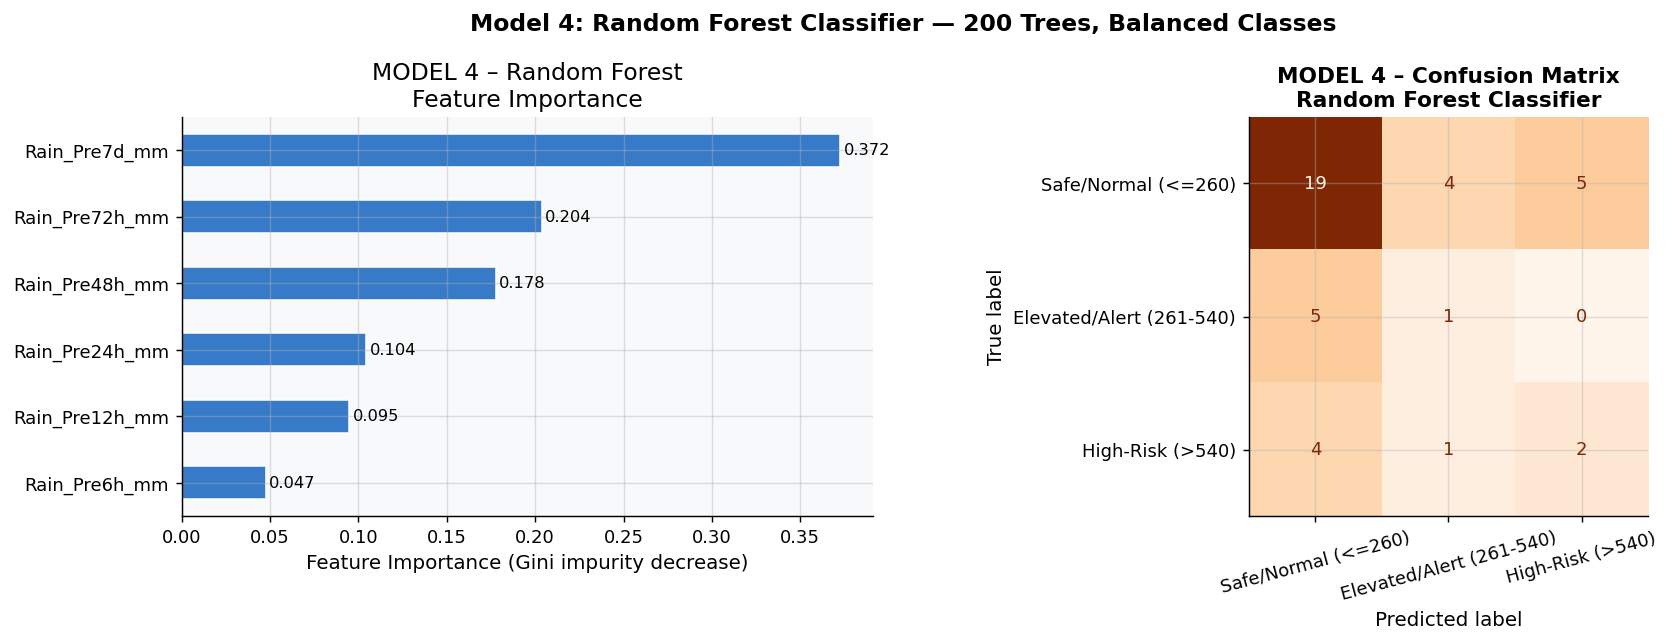

In [19]:
# ══════════════════════════════════════════════════════════════════════
# MODEL 4 – RANDOM FOREST CLASSIFIER
# Task      : 3-class classification (Safe / Elevated / High-Risk)
# Predictors: All 6 antecedent rainfall windows (standardised)
# Library   : sklearn.ensemble.RandomForestClassifier
# ══════════════════════════════════════════════════════════════════════
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics  import (classification_report, accuracy_score,
                               confusion_matrix, fbeta_score,
                               ConfusionMatrixDisplay)

# sklearn RandomForestClassifier (ensemble of decision trees, bagging)
rf = RandomForestClassifier(
    n_estimators=200,     # 200 decision trees
    max_depth=None,       # fully grown trees (controlled by min_samples_leaf)
    min_samples_leaf=2,
    max_features='sqrt',  # √n features per split (default for classification)
    class_weight='balanced',  # handles class imbalance
    random_state=42,
    n_jobs=-1
)
rf.fit(X_tr, yc_tr)
yc_pred_rf = rf.predict(X_te)

acc_rf = accuracy_score(yc_te, yc_pred_rf)
f2_rf  = fbeta_score(yc_te, yc_pred_rf, beta=2, average='weighted')

print("─" * 55)
print("  MODEL 4 : Random Forest Classifier")
print("─" * 55)
print(f"  Algorithm     : sklearn RandomForestClassifier")
print(f"  n_estimators  : 200 decision trees (bagging ensemble)")
print(f"  max_features  : sqrt  (√n features per split)")
print(f"  class_weight  : balanced")
print(f"  Classes       : {list(le.classes_)}")
print(f"  Accuracy      : {acc_rf:.4f}")
print(f"  F2 Score      : {f2_rf:.4f}  (weighted, β=2 emphasises recall)")
print("─" * 55)
print()
print(classification_report(yc_te, yc_pred_rf,
                             target_names=le.classes_, digits=3))

# ── Feature Importance ─────────────────────────────────────────────────
feat_imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
feat_imp.plot.barh(ax=ax, color='#1565C0', alpha=0.85, edgecolor='white')
ax.set_xlabel('Feature Importance (Gini impurity decrease)')
ax.set_title('MODEL 4 – Random Forest\nFeature Importance')
for i, v in enumerate(feat_imp.values):
    ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=9)

# ── Confusion Matrix ───────────────────────────────────────────────────
ax = axes[1]
cm_rf = confusion_matrix(yc_te, yc_pred_rf)
disp  = ConfusionMatrixDisplay(confusion_matrix=cm_rf,
                                display_labels=le.classes_)
disp.plot(ax=ax, colorbar=False, cmap='Oranges',
          xticks_rotation=15)
ax.set_title('MODEL 4 – Confusion Matrix\nRandom Forest Classifier',
             fontsize=12, fontweight='bold')

plt.suptitle('Model 4: Random Forest Classifier — 200 Trees, Balanced Classes',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig13_model4_random_forest.png', bbox_inches='tight')
plt.show()


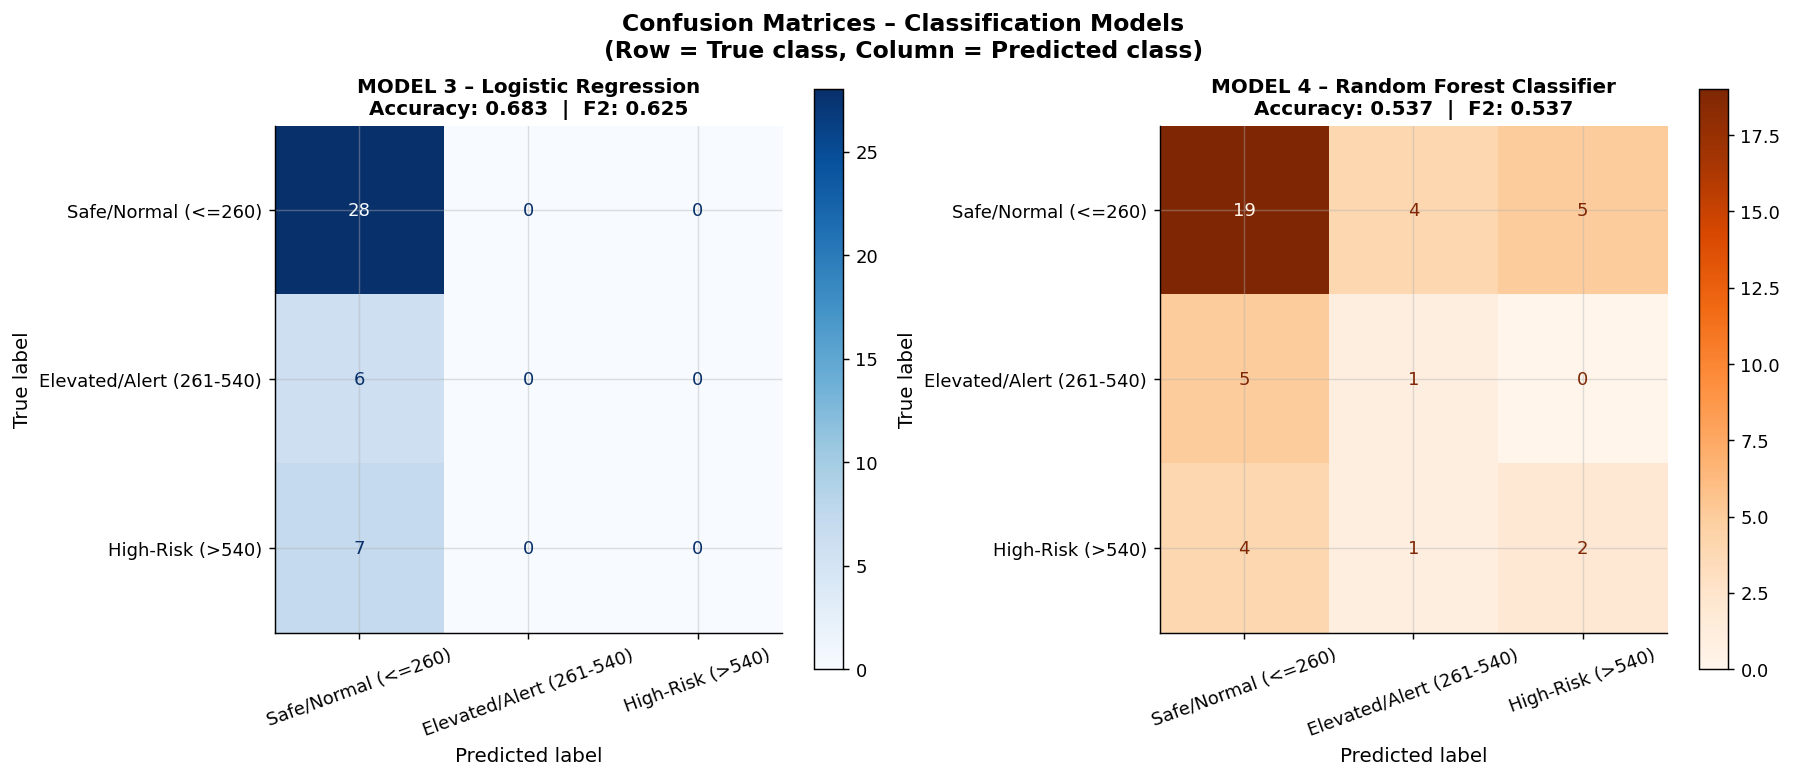


Confusion Matrix – Logistic Regression:
                          Safe/Normal (<=260)  Elevated/Alert (261-540)  High-Risk (>540)
Safe/Normal (<=260)                        28                         0                 0
Elevated/Alert (261-540)                    6                         0                 0
High-Risk (>540)                            7                         0                 0

Confusion Matrix – Random Forest:
                          Safe/Normal (<=260)  Elevated/Alert (261-540)  High-Risk (>540)
Safe/Normal (<=260)                        19                         4                 5
Elevated/Alert (261-540)                    5                         1                 0
High-Risk (>540)                            4                         1                 2


In [20]:
# ══════════════════════════════════════════════════════════════════════
# CONFUSION MATRICES – Side-by-Side Comparison
# Models: Logistic Regression (Model 3) vs Random Forest (Model 4)
# ══════════════════════════════════════════════════════════════════════
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ── Logistic Regression confusion matrix ──────────────────────────────
cm_lr = confusion_matrix(yc_te, yc_pred_lr)
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr,
                                  display_labels=le.classes_)
disp_lr.plot(ax=axes[0], colorbar=True, cmap='Blues', xticks_rotation=20)
axes[0].set_title(
    f'MODEL 3 – Logistic Regression\n'
    f'Accuracy: {accuracy_score(yc_te, yc_pred_lr):.3f}  |  '
    f'F2: {fbeta_score(yc_te, yc_pred_lr, beta=2, average="weighted"):.3f}',
    fontsize=11, fontweight='bold'
)

# ── Random Forest confusion matrix ────────────────────────────────────
cm_rf = confusion_matrix(yc_te, yc_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf,
                                  display_labels=le.classes_)
disp_rf.plot(ax=axes[1], colorbar=True, cmap='Oranges', xticks_rotation=20)
axes[1].set_title(
    f'MODEL 4 – Random Forest Classifier\n'
    f'Accuracy: {accuracy_score(yc_te, yc_pred_rf):.3f}  |  '
    f'F2: {fbeta_score(yc_te, yc_pred_rf, beta=2, average="weighted"):.3f}',
    fontsize=11, fontweight='bold'
)

plt.suptitle(
    'Confusion Matrices – Classification Models\n'
    '(Row = True class, Column = Predicted class)',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig('fig14_confusion_matrices_combined.png', bbox_inches='tight')
plt.show()

print("\nConfusion Matrix – Logistic Regression:")
print(pd.DataFrame(cm_lr, index=le.classes_, columns=le.classes_).to_string())
print("\nConfusion Matrix – Random Forest:")
print(pd.DataFrame(cm_rf, index=le.classes_, columns=le.classes_).to_string())


,Accuracy,Precision,Recall,F1,F2
Model,,,,,
Logistic Regression,0.6829,0.4664,0.6829,0.5543,0.6249
Random Forest,0.5366,0.5366,0.5366,0.5366,0.5366


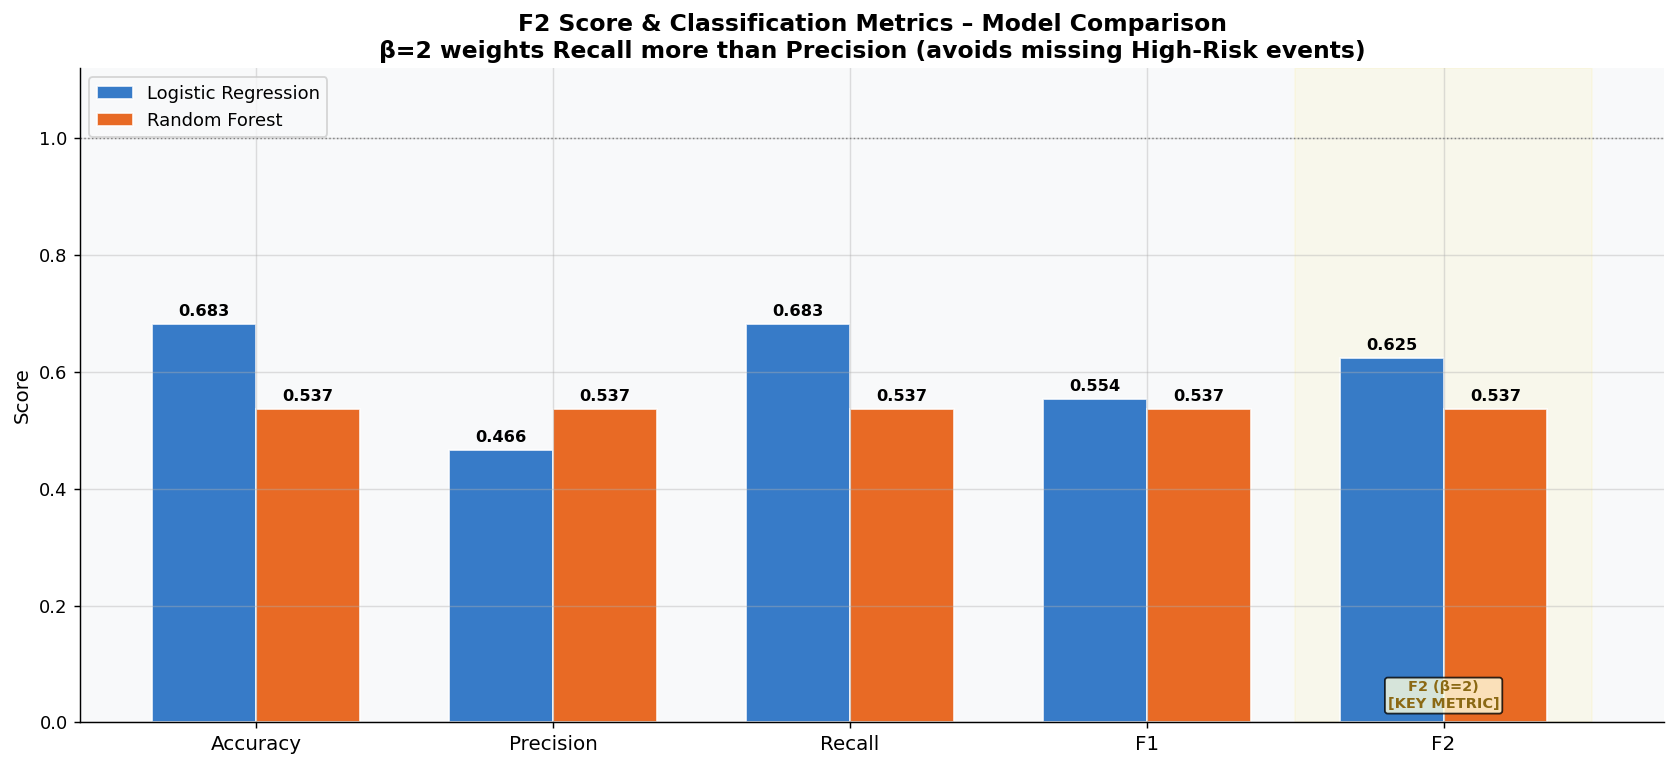


  F2 Score Summary (β=2, weighted average):
  Logistic Regression      : F2 = 0.6249
  Random Forest            : F2 = 0.5366

  F2 emphasises Recall (β=2 → recall weighted 4× precision).
  For water-quality safety, missing a HIGH-RISK event is the
  worst outcome, so high F2 is the preferred model metric.


In [21]:
# ══════════════════════════════════════════════════════════════════════
# F2 SCORE (Fβ with β=2) – MODEL COMPARISON FIGURE
# β=2 weights RECALL twice as heavily as PRECISION
# Rationale: False negatives (missing a High-Risk event) are more costly
#            than false positives in water-quality safety contexts.
# ══════════════════════════════════════════════════════════════════════
from sklearn.metrics import fbeta_score, precision_score, recall_score, f1_score

models_clf  = ['Logistic Regression', 'Random Forest']
preds_clf   = [yc_pred_lr,            yc_pred_rf]
palette_clf = [SITE1_CLR,             SITE2_CLR]

# Compute per-model metrics ─────────────────────────────────────────────
metrics_rows = []
for name, pred in zip(models_clf, preds_clf):
    row = dict(
        Model     = name,
        Accuracy  = accuracy_score(yc_te, pred),
        Precision = precision_score(yc_te, pred, average='weighted', zero_division=0),
        Recall    = recall_score(yc_te, pred,    average='weighted', zero_division=0),
        F1        = f1_score(yc_te, pred,         average='weighted', zero_division=0),
        F2        = fbeta_score(yc_te, pred, beta=2, average='weighted', zero_division=0),
    )
    metrics_rows.append(row)

metrics_df = pd.DataFrame(metrics_rows).set_index('Model')
display(metrics_df.round(4))

# ── Figure: grouped bar chart ──────────────────────────────────────────
metric_names = ['Accuracy','Precision','Recall','F1','F2']
n_models = len(models_clf)
n_metrics = len(metric_names)
x = np.arange(n_metrics)
width = 0.35

fig, ax = plt.subplots(figsize=(13, 6))
for i, (name, clr) in enumerate(zip(models_clf, palette_clf)):
    vals = [metrics_df.loc[name, m] for m in metric_names]
    bars = ax.bar(x + i*width - width/2, vals, width,
                  label=name, color=clr, alpha=0.85, edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.008,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# Highlight F2 column
ax.axvspan(x[-1] - 0.5, x[-1] + 0.5, alpha=0.06, color='gold', zorder=0)
ax.text(x[-1], 0.02, 'F2 (β=2)\n[KEY METRIC]', ha='center', va='bottom',
        fontsize=8, color='#8B6914', fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', fc='lightyellow', alpha=0.8))

ax.set_xticks(x)
ax.set_xticklabels(metric_names, fontsize=11)
ax.set_ylabel('Score', fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_title(
    'F2 Score & Classification Metrics – Model Comparison\n'
    'β=2 weights Recall more than Precision (avoids missing High-Risk events)',
    fontsize=13, fontweight='bold'
)
ax.legend(fontsize=10, loc='upper left')
ax.axhline(1.0, color='grey', lw=0.8, ls=':')

plt.tight_layout()
plt.savefig('fig15_f2_score_model_comparison.png', bbox_inches='tight')
plt.show()

print("\n  F2 Score Summary (β=2, weighted average):")
for name in models_clf:
    print(f"  {name:<25s}: F2 = {metrics_df.loc[name,'F2']:.4f}")
print("\n  F2 emphasises Recall (β=2 → recall weighted 4× precision).")
print("  For water-quality safety, missing a HIGH-RISK event is the")
print("  worst outcome, so high F2 is the preferred model metric.")


Monthly series length : 64 months
Range : 2021-01-01 → 2026-04-01
Mean  : 2.074  |  Std: 0.532

── STL Decomposition Summary ────────────────────────────────
  Trend     range : [1.793, 2.205]
  Seasonal  range : [-1.564, 0.966]
  Residual  std   : 0.4088


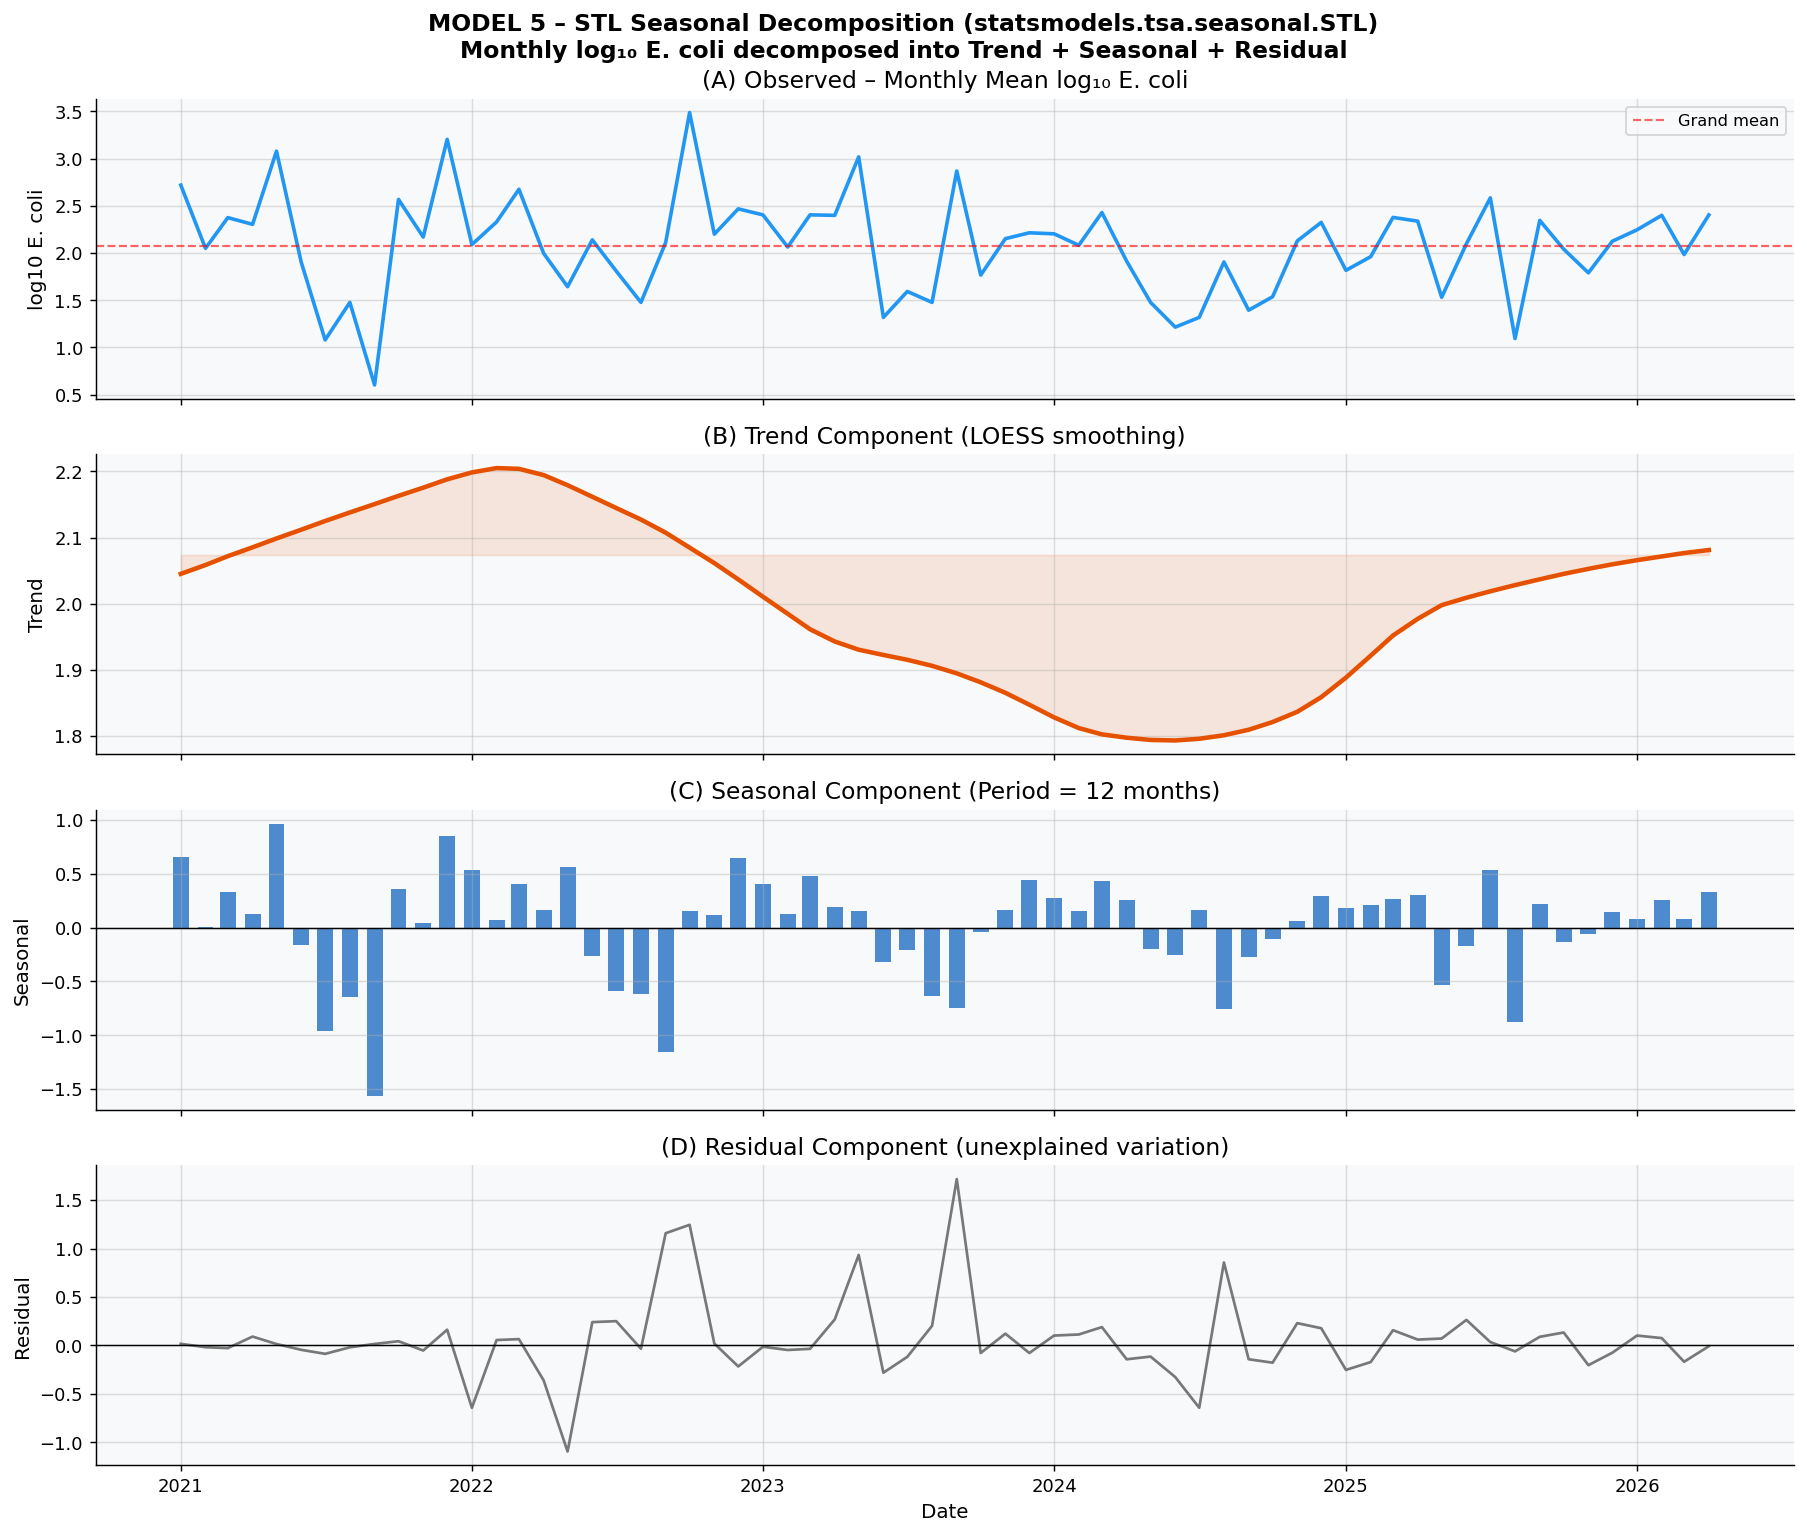

In [22]:
# ══════════════════════════════════════════════════════════════════════
# MODEL 5 – SEASONAL DECOMPOSITION (STL – Seasonal and Trend
#            decomposition using LOESS)
# Library  : statsmodels.tsa.seasonal.STL
# Input    : Monthly mean log10 E. coli (pooled, both sites)
# ══════════════════════════════════════════════════════════════════════
from statsmodels.tsa.seasonal import STL, seasonal_decompose

# ── Build a regular monthly time series ───────────────────────────────
ts_monthly = (df.set_index('DateTime')['Log10_Ecoli']
               .resample('MS')          # month-start
               .mean()
               .dropna())

print(f"Monthly series length : {len(ts_monthly)} months")
print(f"Range : {ts_monthly.index[0].date()} → {ts_monthly.index[-1].date()}")
print(f"Mean  : {ts_monthly.mean():.3f}  |  Std: {ts_monthly.std():.3f}")

# STL decomposition (robust=True for outlier resistance)
stl = STL(ts_monthly, period=12, robust=True)
stl_res = stl.fit()

print("\n── STL Decomposition Summary ────────────────────────────────")
print(f"  Trend     range : [{stl_res.trend.min():.3f}, {stl_res.trend.max():.3f}]")
print(f"  Seasonal  range : [{stl_res.seasonal.min():.3f}, {stl_res.seasonal.max():.3f}]")
print(f"  Residual  std   : {stl_res.resid.std():.4f}")

# ── Plot ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

axes[0].plot(ts_monthly.index, ts_monthly.values, color=SAFE_CLR, lw=2)
axes[0].set_ylabel('log10 E. coli')
axes[0].set_title('(A) Observed – Monthly Mean log₁₀ E. coli')
axes[0].axhline(ts_monthly.mean(), color='red', lw=1.2, ls='--', alpha=0.6, label='Grand mean')
axes[0].legend(fontsize=9)

axes[1].plot(ts_monthly.index, stl_res.trend, color='#E65100', lw=2.5)
axes[1].set_ylabel('Trend')
axes[1].set_title('(B) Trend Component (LOESS smoothing)')
axes[1].fill_between(ts_monthly.index, stl_res.trend, ts_monthly.mean(),
                      alpha=0.12, color='#E65100')

axes[2].bar(ts_monthly.index, stl_res.seasonal, color='#1565C0', alpha=0.75, width=20)
axes[2].axhline(0, color='black', lw=0.8)
axes[2].set_ylabel('Seasonal')
axes[2].set_title('(C) Seasonal Component (Period = 12 months)')

axes[3].plot(ts_monthly.index, stl_res.resid, color='#616161', lw=1.5, alpha=0.85)
axes[3].axhline(0, color='black', lw=0.8)
axes[3].set_ylabel('Residual')
axes[3].set_xlabel('Date')
axes[3].set_title('(D) Residual Component (unexplained variation)')

plt.suptitle(
    'MODEL 5 – STL Seasonal Decomposition (statsmodels.tsa.seasonal.STL)\n'
    'Monthly log₁₀ E. coli decomposed into Trend + Seasonal + Residual',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig('fig16_model5_stl_decomposition.png', bbox_inches='tight')
plt.show()


─────────────────────────────────────────────────────────────────
  MODEL 6 : SARIMA(1,1,1)(1,1,1)[12]
─────────────────────────────────────────────────────────────────
  Library      : statsmodels SARIMAX
  Non-seasonal : AR(1) I(1) MA(1)
  Seasonal     : SAR(1) SI(1) SMA(1), period s=12 months
  AIC          : 72.30
  BIC          : 80.35
  Log-lik      : -31.15
─────────────────────────────────────────────────────────────────
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1709      0.225     -0.761      0.447      -0.611       0.270
ma.L1         -0.8794      0.219     -4.014      0.000      -1.309      -0.450
ar.S.L12      -0.2365      0.146     -1.615      0.106      -0.524       0.051
ma.S.L12      -1.0008    345.208     -0.003      0.998    -677.596     675.594
sigma2         0.1995     68.908      0.003      0.998    -134.858     135.257


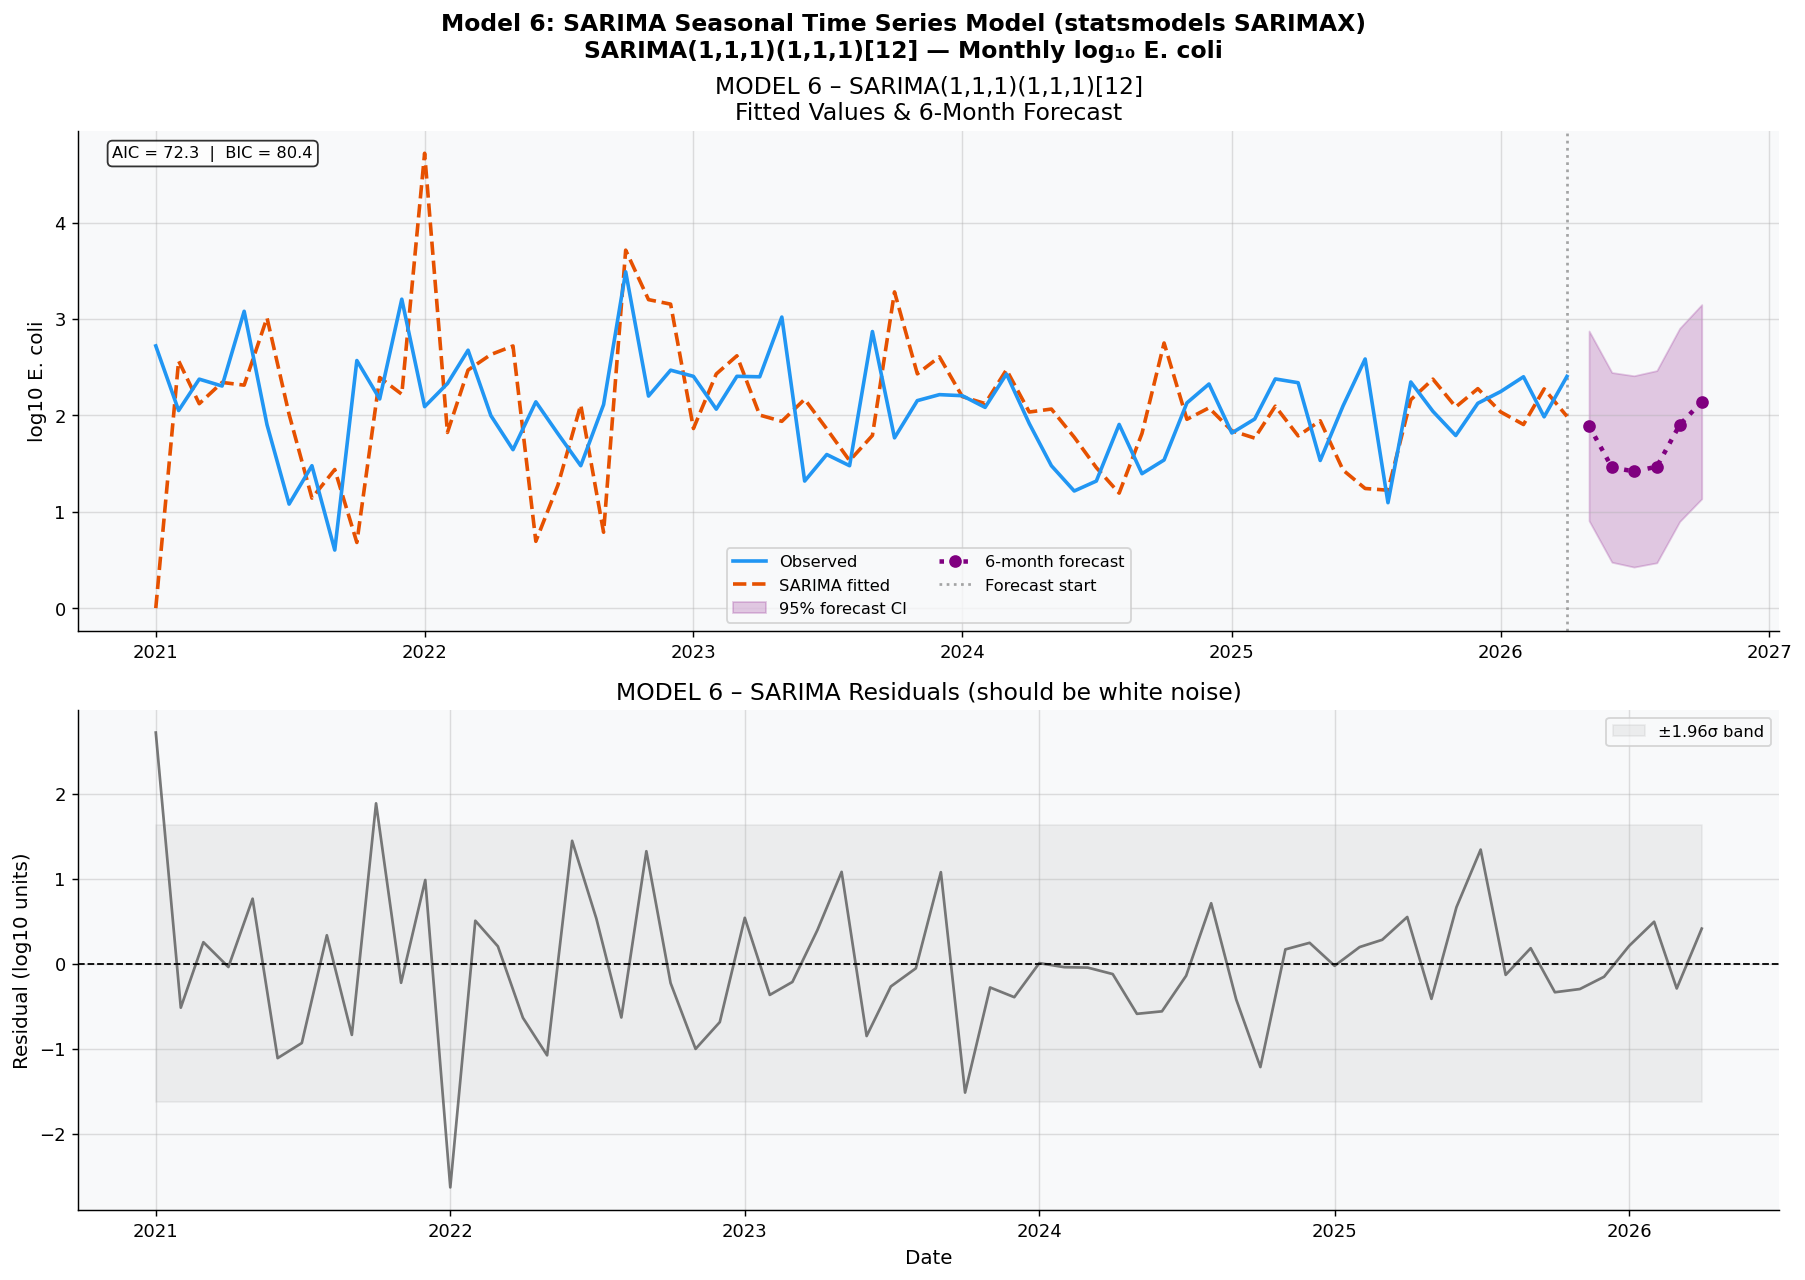


  6-Month Forecast:
   Date  Pred log10  Lower 95%  Upper 95%
2026-05       1.891      0.906      2.875
2026-06       1.460      0.476      2.444
2026-07       1.418      0.426      2.410
2026-08       1.467      0.470      2.464
2026-09       1.900      0.898      2.902
2026-10       2.141      1.134      3.148


In [23]:
# ══════════════════════════════════════════════════════════════════════
# MODEL 6 – SARIMA (Seasonal AutoRegressive Integrated Moving Average)
# Library  : statsmodels.tsa.statespace.sarimax.SARIMAX
# Order    : SARIMA(1,1,1)(1,1,1)[12]
#   p=1 AR term | d=1 differencing | q=1 MA term
#   P=1 seasonal AR | D=1 seasonal differencing | Q=1 seasonal MA
#   s=12 (annual seasonality, monthly data)
# ══════════════════════════════════════════════════════════════════════
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings('ignore')

# ── Fit SARIMA(1,1,1)(1,1,1)[12] ──────────────────────────────────────
sarima_model = SARIMAX(
    ts_monthly,
    order=(1, 1, 1),             # (p, d, q)  – non-seasonal
    seasonal_order=(1, 1, 1, 12),# (P, D, Q, s) – seasonal (12-month cycle)
    enforce_stationarity=False,
    enforce_invertibility=False
)
sarima_fit = sarima_model.fit(disp=False)

print("─" * 65)
print("  MODEL 6 : SARIMA(1,1,1)(1,1,1)[12]")
print("─" * 65)
print(f"  Library      : statsmodels SARIMAX")
print(f"  Non-seasonal : AR(1) I(1) MA(1)")
print(f"  Seasonal     : SAR(1) SI(1) SMA(1), period s=12 months")
print(f"  AIC          : {sarima_fit.aic:.2f}")
print(f"  BIC          : {sarima_fit.bic:.2f}")
print(f"  Log-lik      : {sarima_fit.llf:.2f}")
print("─" * 65)
print(sarima_fit.summary().tables[1])

# ── In-sample fitted values ───────────────────────────────────────────
fitted_vals   = sarima_fit.fittedvalues
residuals_sar = ts_monthly - fitted_vals

# ── Forecast: next 6 months ───────────────────────────────────────────
forecast_steps = 6
forecast = sarima_fit.get_forecast(steps=forecast_steps)
fc_mean  = forecast.predicted_mean
fc_ci    = forecast.conf_int(alpha=0.05)

# ── Plot ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

ax = axes[0]
ax.plot(ts_monthly.index, ts_monthly.values,
        color=SAFE_CLR, lw=2, label='Observed', zorder=4)
ax.plot(fitted_vals.index, fitted_vals.values,
        color='#E65100', lw=2, ls='--', label='SARIMA fitted', zorder=3)
ax.fill_between(fc_mean.index, fc_ci.iloc[:, 0], fc_ci.iloc[:, 1],
                alpha=0.2, color='purple', label='95% forecast CI')
ax.plot(fc_mean.index, fc_mean.values,
        color='purple', lw=2.5, ls=':', marker='o', ms=6, label='6-month forecast')
ax.axvline(ts_monthly.index[-1], color='grey', lw=1.5, ls=':', alpha=0.7,
           label='Forecast start')
ax.set_ylabel('log10 E. coli')
ax.set_title('MODEL 6 – SARIMA(1,1,1)(1,1,1)[12]\nFitted Values & 6-Month Forecast')
ax.legend(fontsize=9, ncol=2)
ax.text(0.02, 0.97, f'AIC = {sarima_fit.aic:.1f}  |  BIC = {sarima_fit.bic:.1f}',
        transform=ax.transAxes, va='top', fontsize=9,
        bbox=dict(boxstyle='round', fc='white', alpha=0.8))

ax = axes[1]
ax.plot(residuals_sar.index, residuals_sar.values,
        color='#616161', lw=1.5, alpha=0.85)
ax.axhline(0, color='black', lw=1.0, ls='--')
ax.fill_between(residuals_sar.index,
                -residuals_sar.std()*1.96, residuals_sar.std()*1.96,
                alpha=0.1, color='grey', label='±1.96σ band')
ax.set_ylabel('Residual (log10 units)')
ax.set_xlabel('Date')
ax.set_title('MODEL 6 – SARIMA Residuals (should be white noise)')
ax.legend(fontsize=9)

plt.suptitle(
    'Model 6: SARIMA Seasonal Time Series Model (statsmodels SARIMAX)\n'
    'SARIMA(1,1,1)(1,1,1)[12] — Monthly log₁₀ E. coli',
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.savefig('fig17_model6_sarima.png', bbox_inches='tight')
plt.show()

print("\n  6-Month Forecast:")
print(pd.DataFrame({
    'Date'   : fc_mean.index.strftime('%Y-%m'),
    'Pred log10': fc_mean.values.round(3),
    'Lower 95%' : fc_ci.iloc[:,0].values.round(3),
    'Upper 95%' : fc_ci.iloc[:,1].values.round(3),
}).to_string(index=False))


## Four additional E. coli classification models (Models 7–10)

Decision Tree, SVM, KNN and Gradient Boosting. The next cell also **re-trains Logistic Regression and Random Forest** on the identical stratified train/test split for fair comparison. It prints measured scores and creates **eight PNG figures** (four individual confusion matrices, one six-model confusion matrix grid, one metric comparison, one feature-importance comparison and one decision-tree diagram). Figures are calculated from the Excel dataset when the notebook runs; they are not fabricated.

**Data required:** `Ecoli and LagRainfall.xlsx` in the notebook working directory.


Model 3: Logistic Regression
                          precision    recall  f1-score   support

     Safe/Normal (<=260)       0.82      0.96      0.89        28
Elevated/Alert (261-540)       0.33      0.17      0.22         6
        High-Risk (>540)       0.80      0.57      0.67         7

                accuracy                           0.78        41
               macro avg       0.65      0.57      0.59        41
            weighted avg       0.74      0.78      0.75        41




Model 4: Random Forest
                          precision    recall  f1-score   support

     Safe/Normal (<=260)       0.84      0.93      0.88        28
Elevated/Alert (261-540)       0.33      0.33      0.33         6
        High-Risk (>540)       0.75      0.43      0.55         7

                accuracy                           0.76        41
               macro avg       0.64      0.56      0.59        41
            weighted avg       0.75      0.76      0.74        41


Model 7: Decision Tree
                          precision    recall  f1-score   support

     Safe/Normal (<=260)       0.82      0.82      0.82        28
Elevated/Alert (261-540)       0.12      0.17      0.14         6
        High-Risk (>540)       0.20      0.14      0.17         7

                accuracy                           0.61        41
               macro avg       0.38      0.38      0.38        41
            weighted avg       0.61      0.61      0.61        41


Model 8: Support Vect


Model 10: Gradient Boosting
                          precision    recall  f1-score   support

     Safe/Normal (<=260)       0.81      0.89      0.85        28
Elevated/Alert (261-540)       0.33      0.17      0.22         6
        High-Risk (>540)       0.57      0.57      0.57         7

                accuracy                           0.73        41
               macro avg       0.57      0.54      0.55        41
            weighted avg       0.70      0.73      0.71        41



,Model,Accuracy,Precision,Recall,F1,F2,High-risk recall
0,Model 3: Logistic Regression,0.780,0.744,0.780,0.751,0.766,0.571
1,Model 4: Random Forest,0.756,0.750,0.756,0.744,0.750,0.429
4,Model 9: K-Nearest Neighbours,0.756,0.723,0.756,0.727,0.742,0.429
5,Model 10: Gradient Boosting,0.732,0.697,0.732,0.709,0.722,0.571
3,Model 8: Support Vector Machine,0.707,0.716,0.707,0.711,0.709,0.571
2,Model 7: Decision Tree,0.610,0.613,0.610,0.610,0.610,0.143


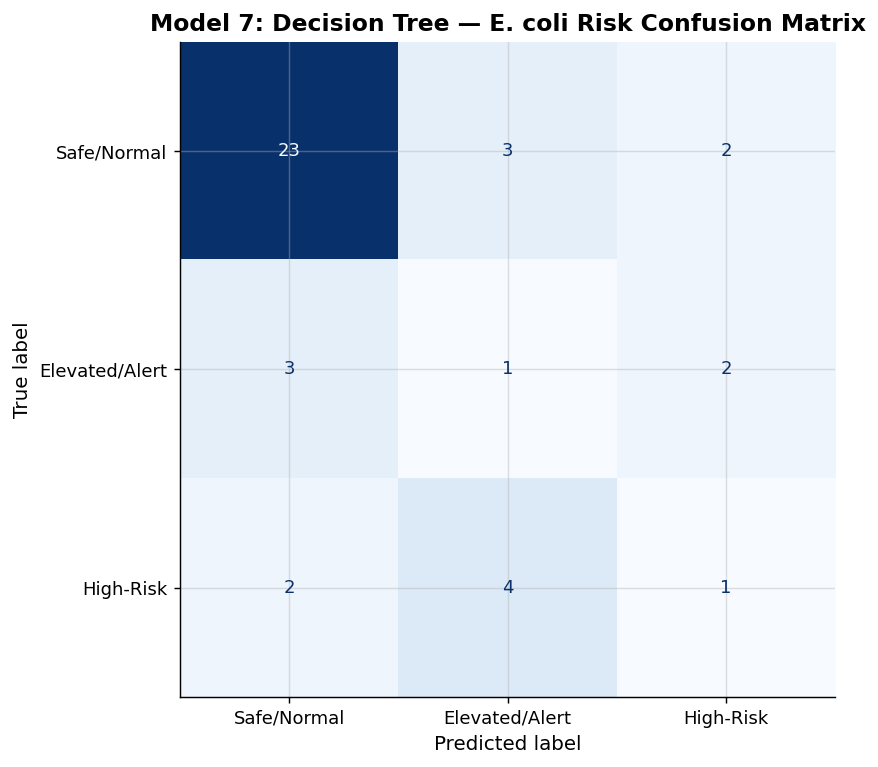

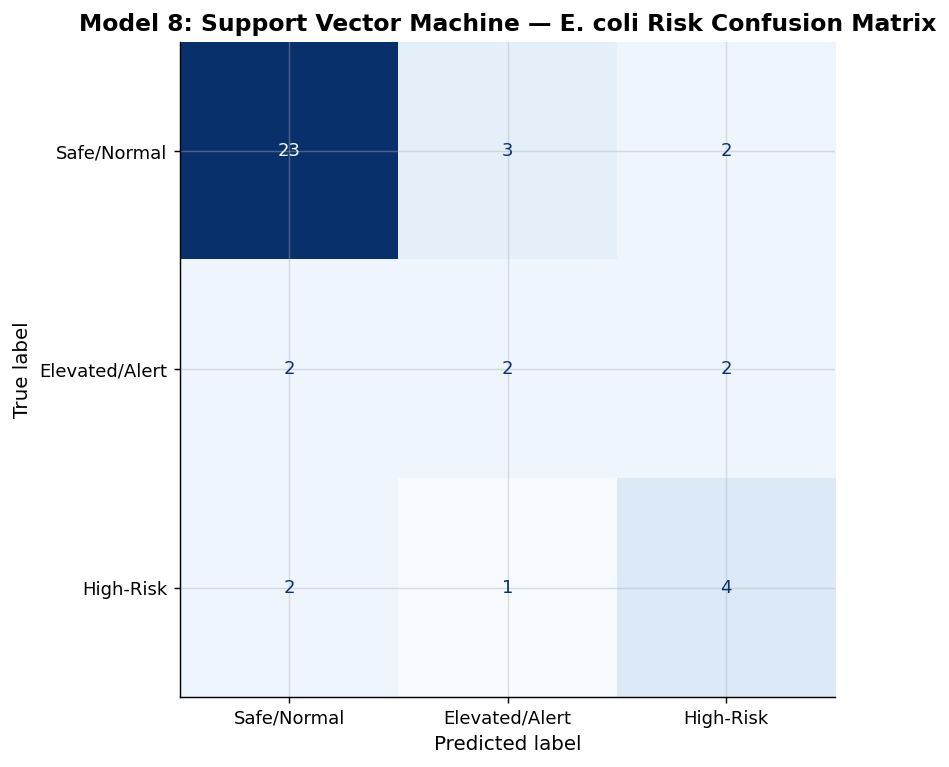

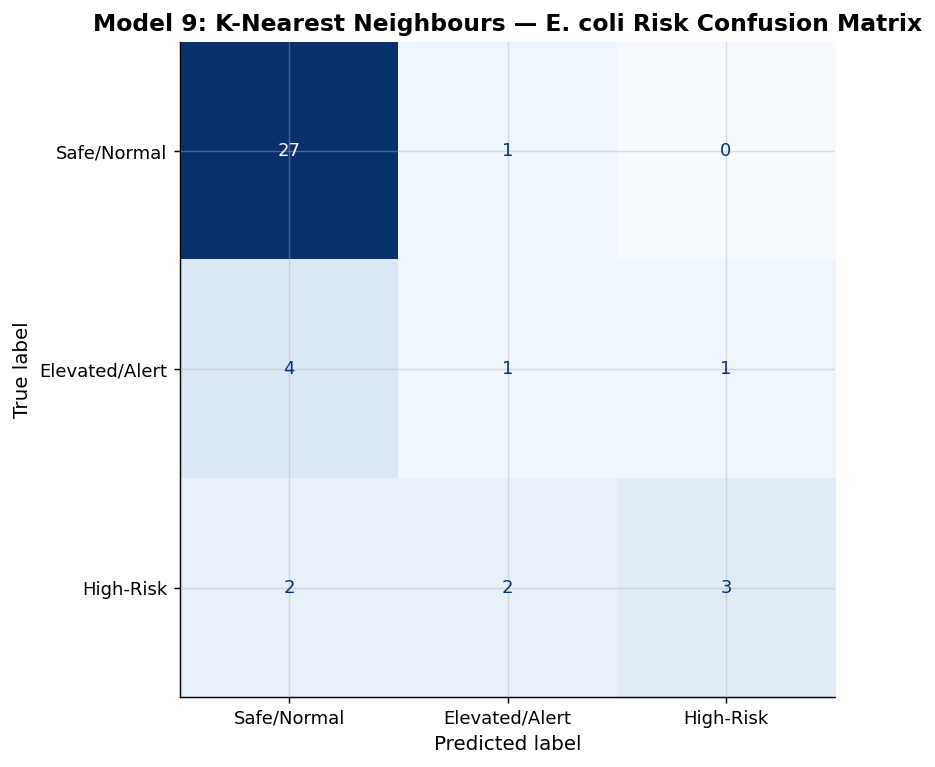

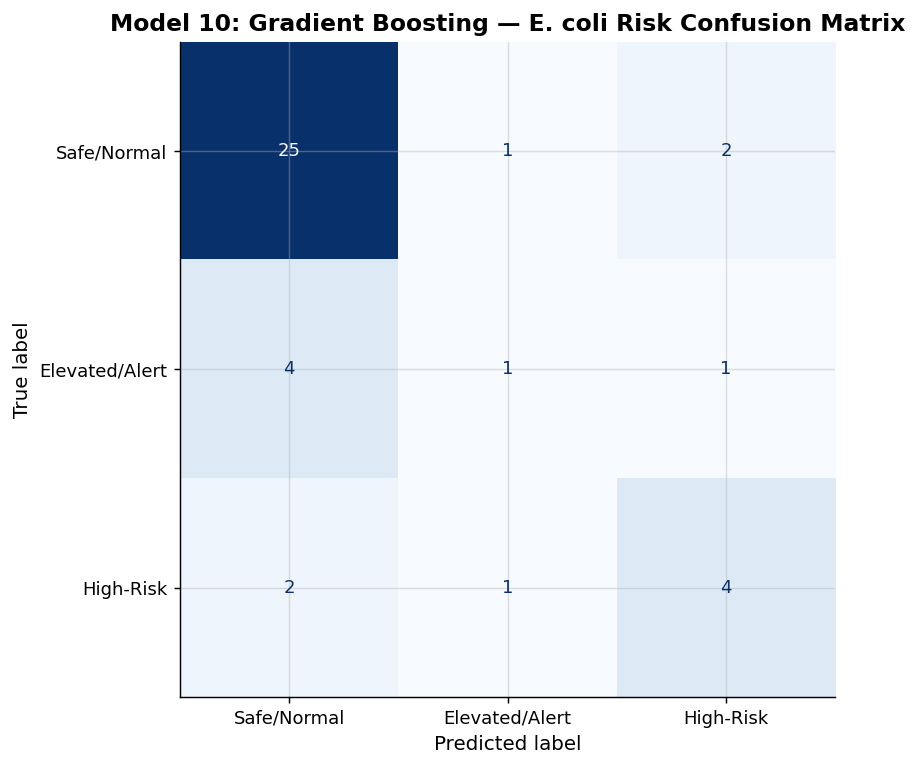

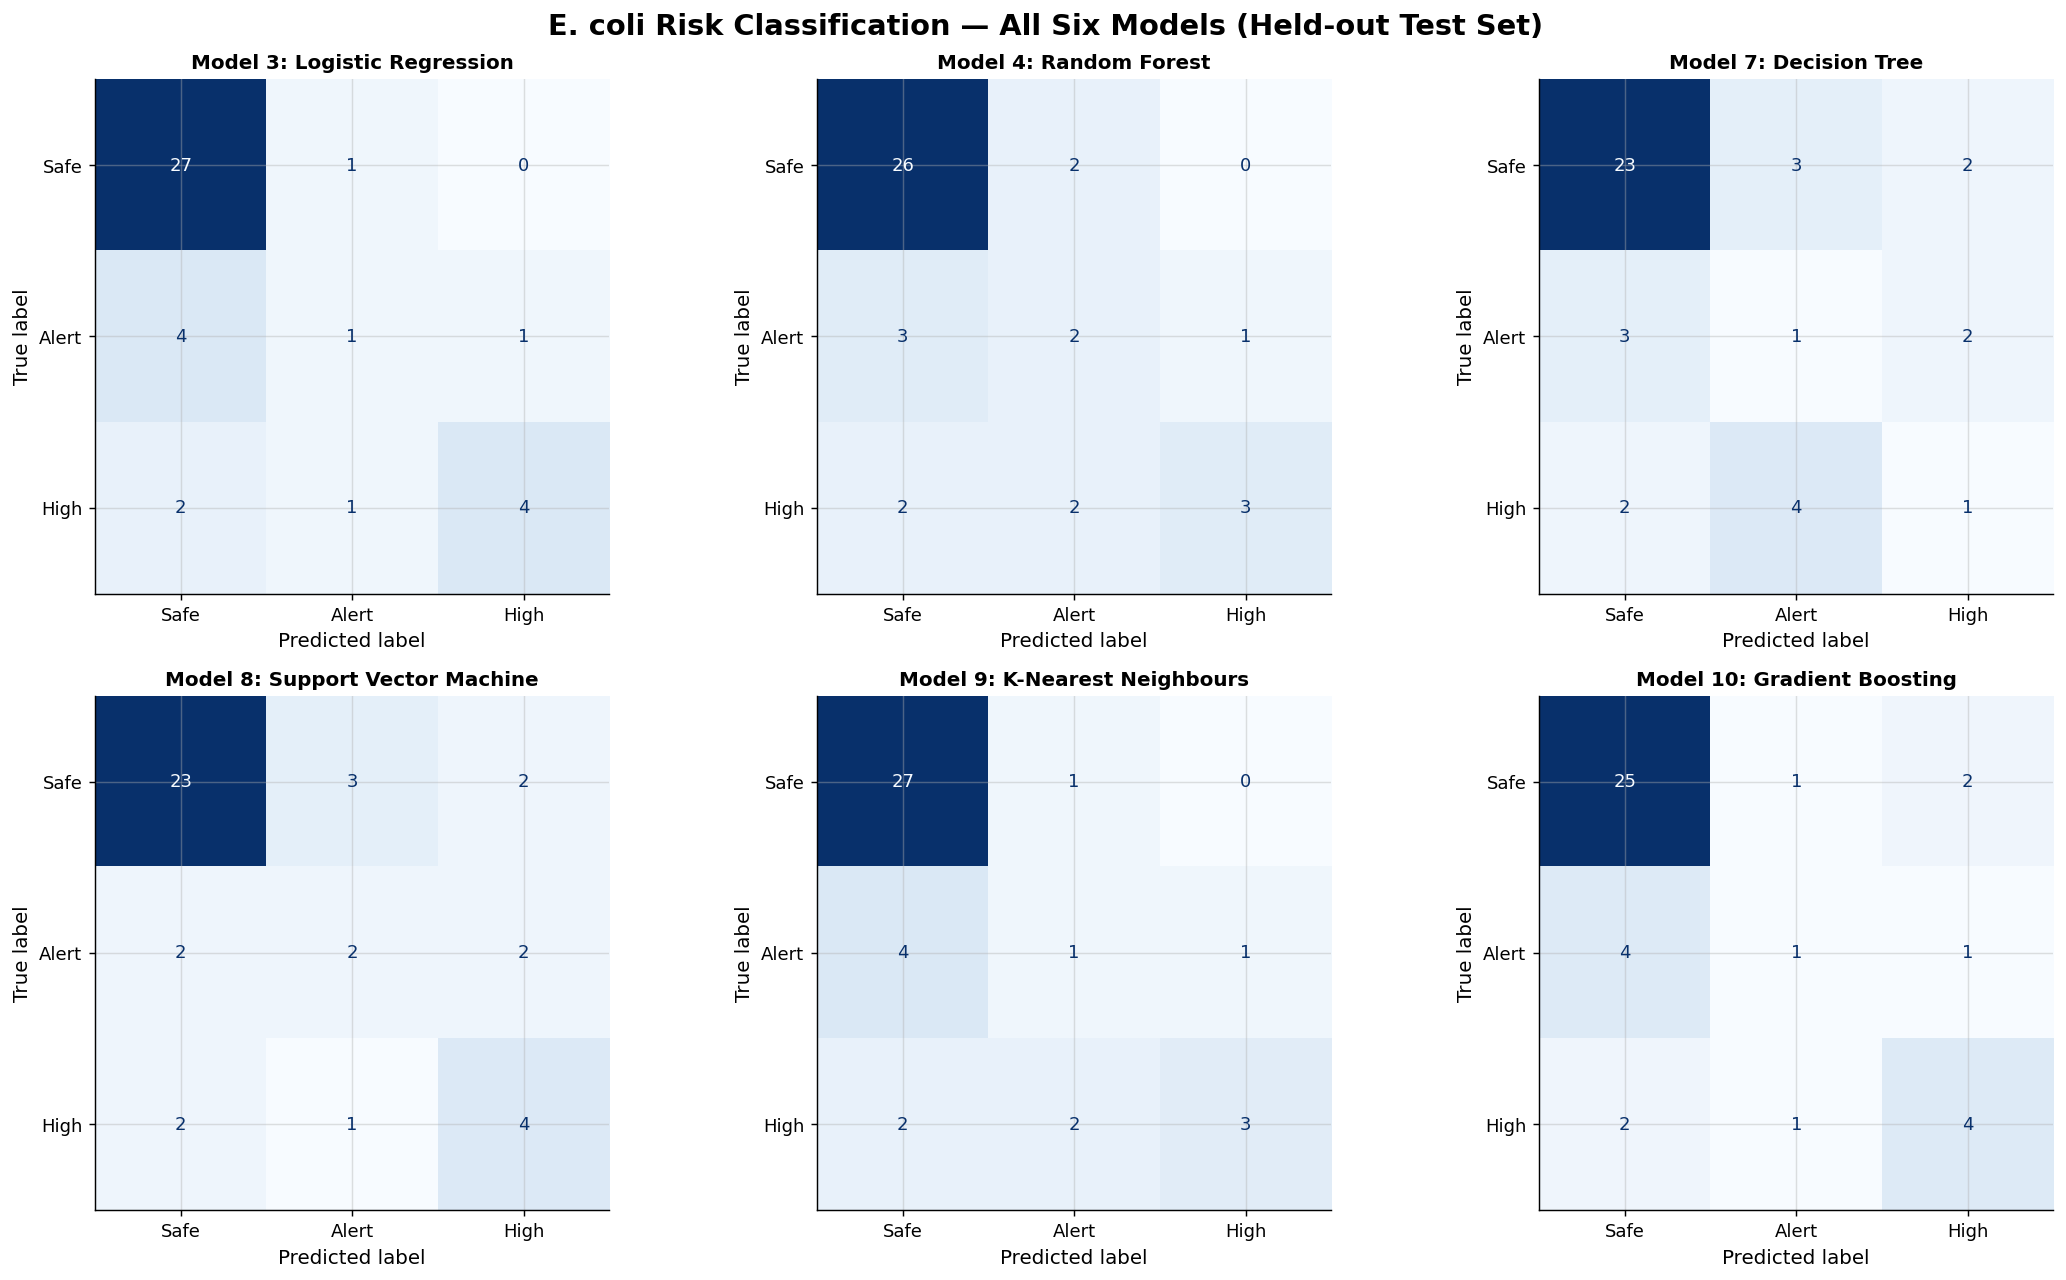

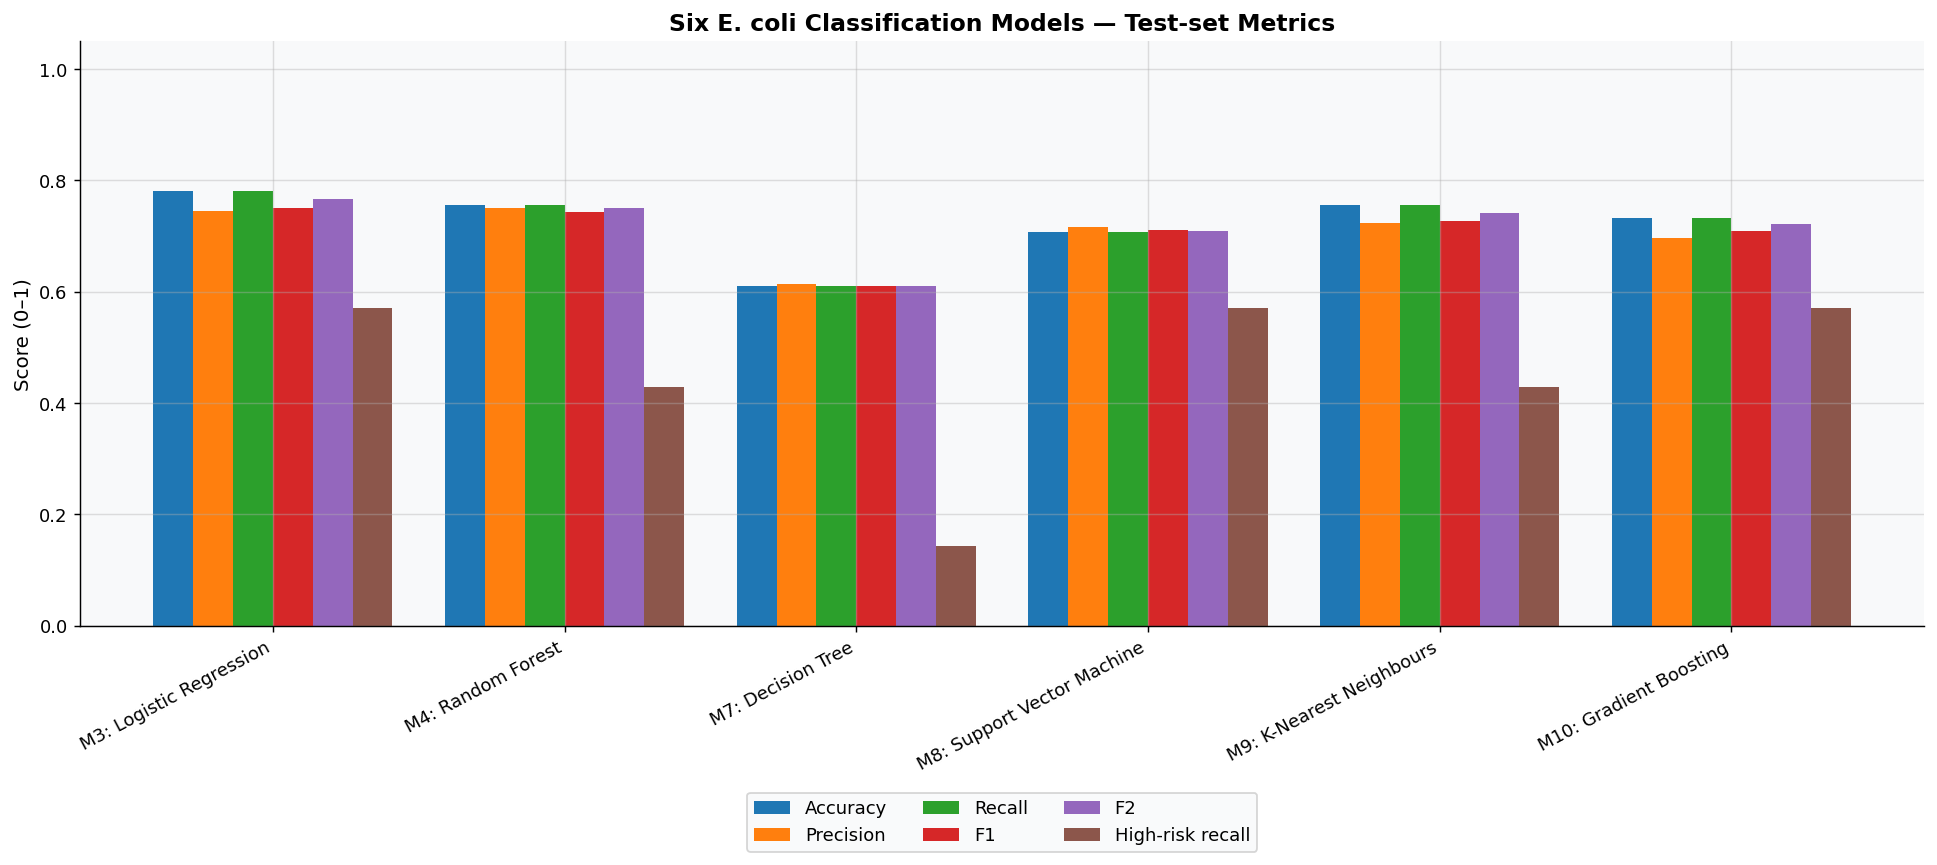

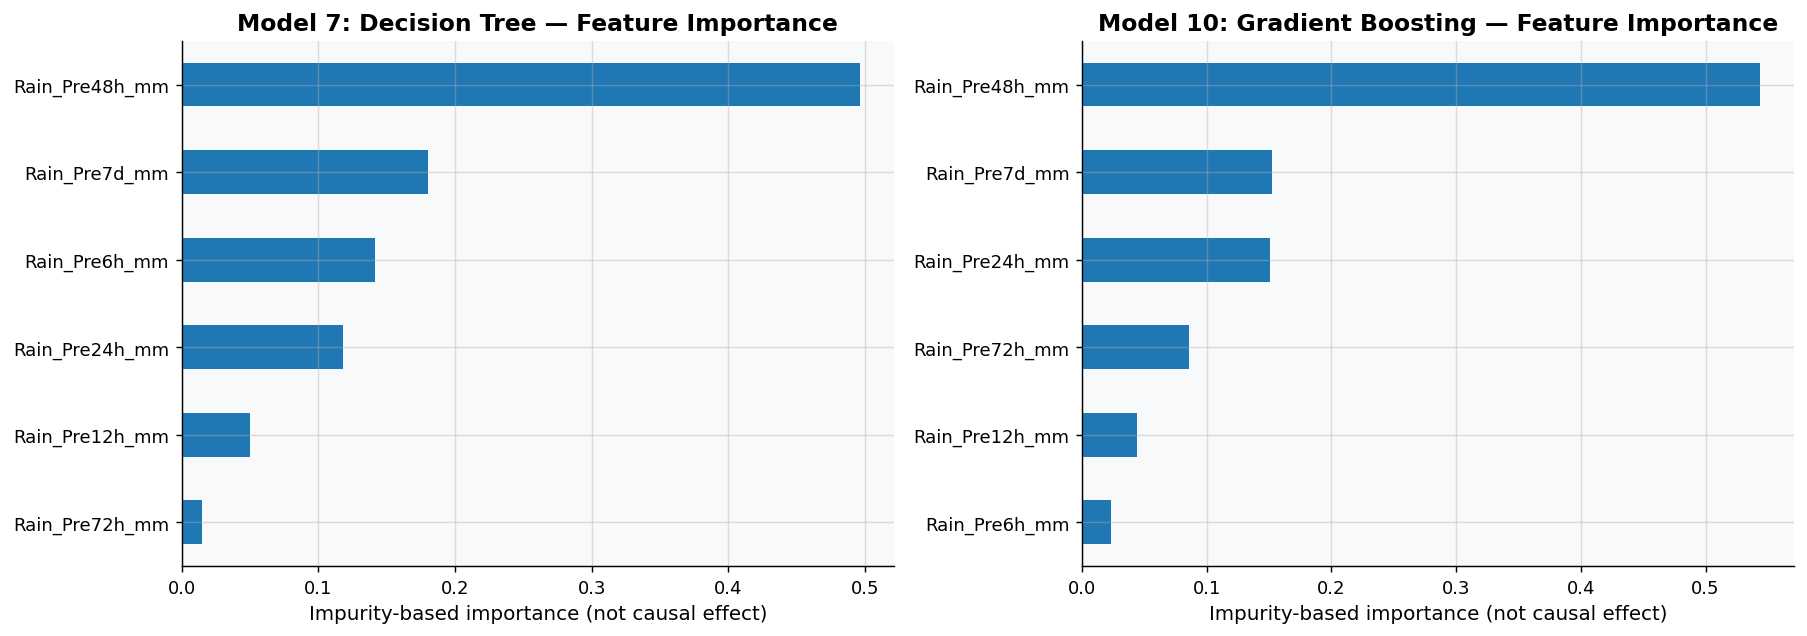

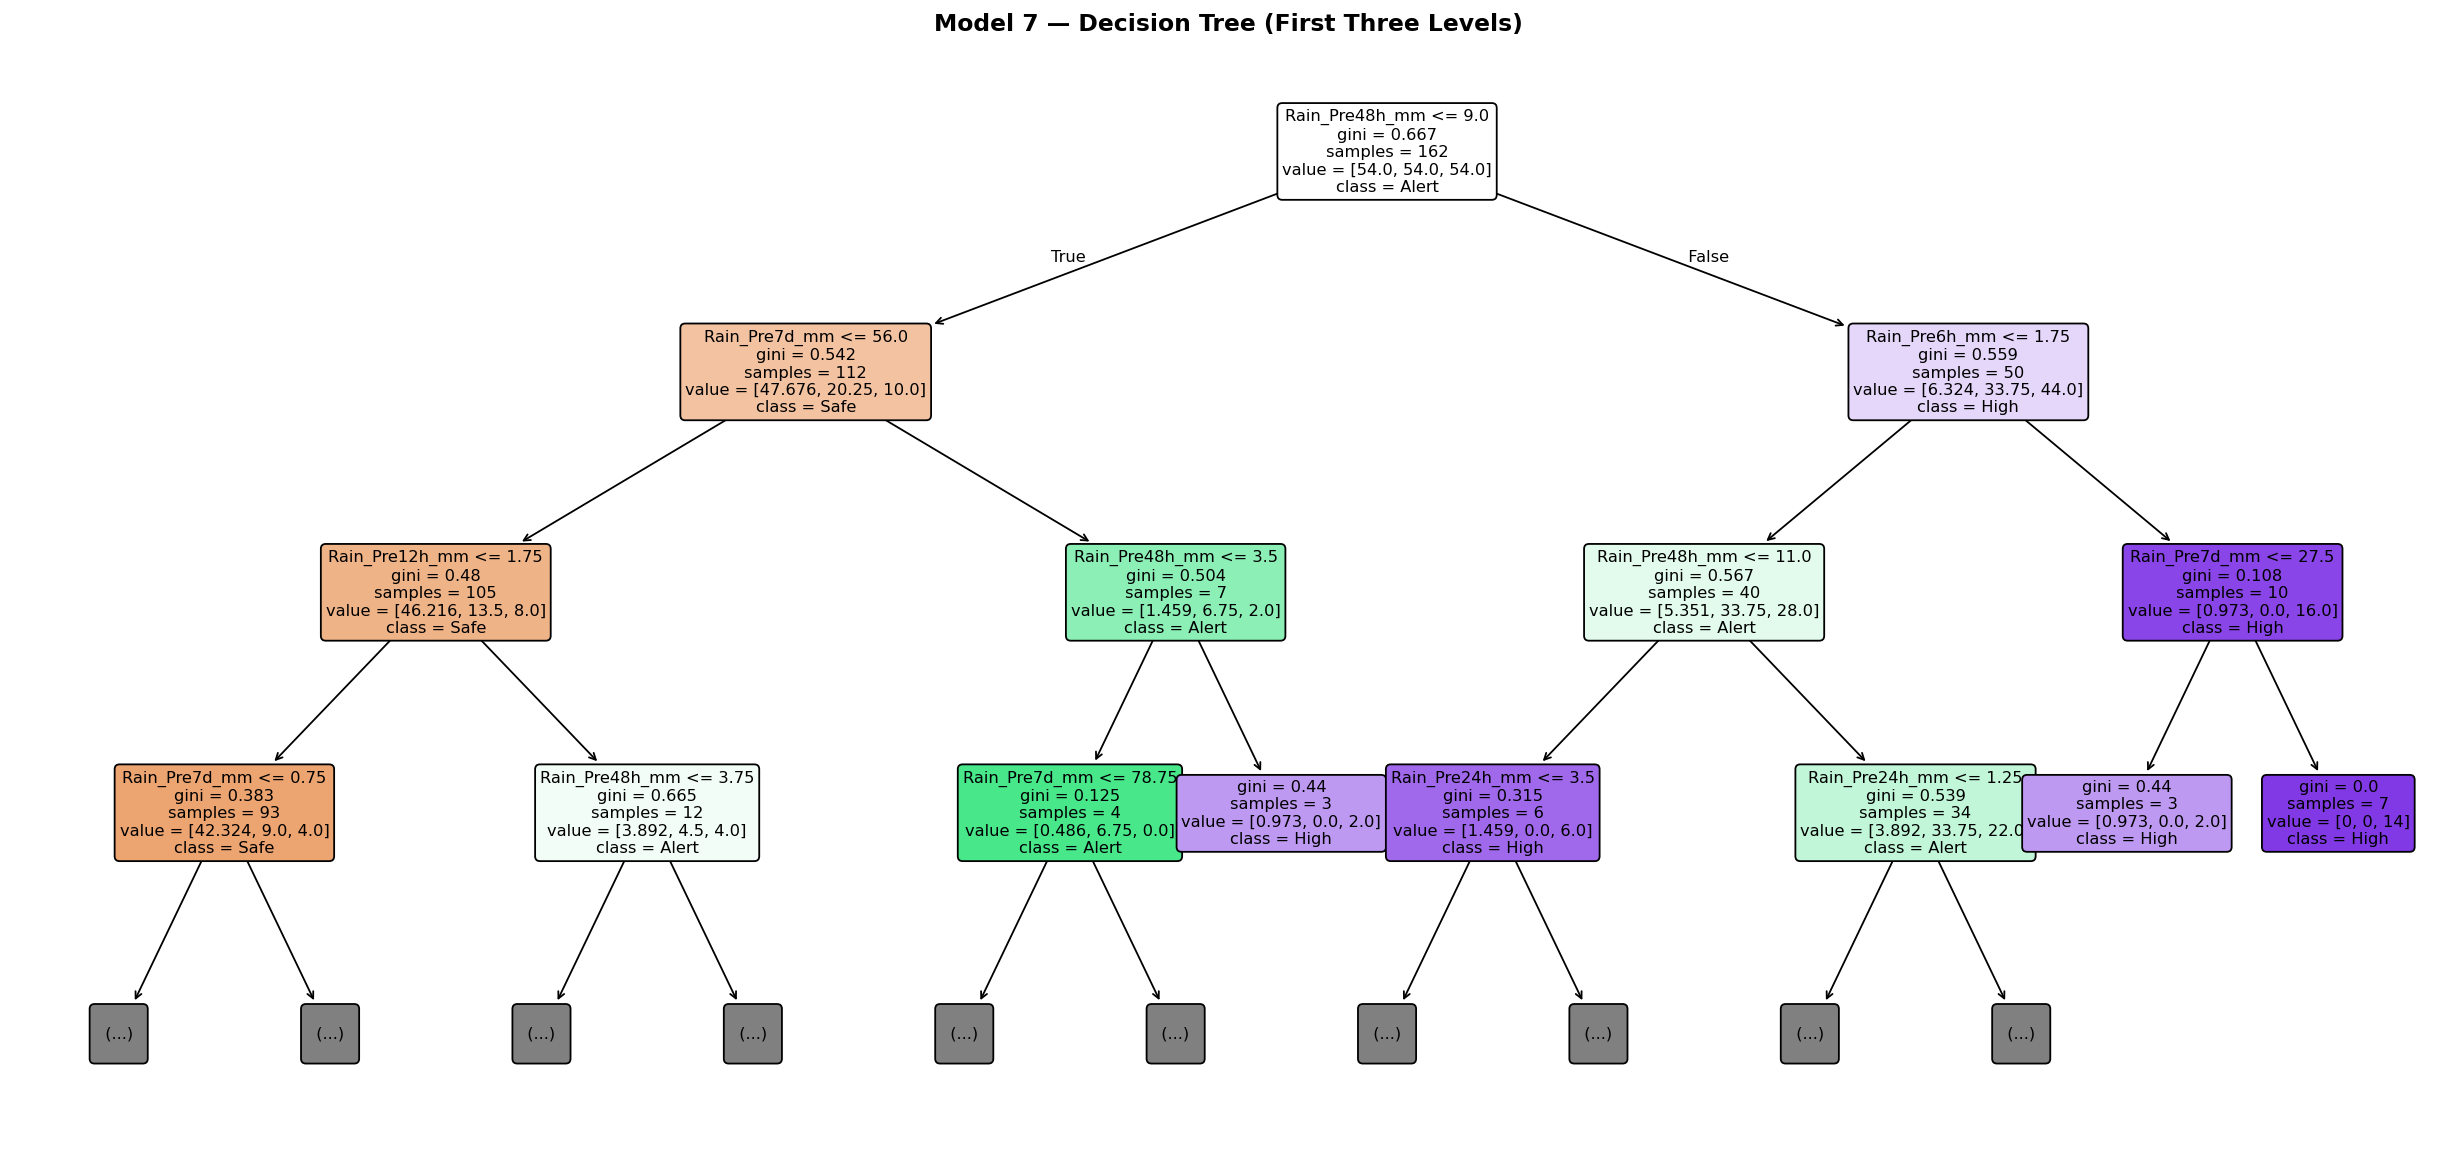


Figures and metrics saved in: /mnt/data/ecoli_classification_figures
Important: These are held-out test scores, not cross-validated estimates.


In [24]:
# MODELS 7–10: FOUR ADDITIONAL E. COLI RISK CLASSIFIERS
# All six classifiers below are evaluated on the SAME held-out observations.
# Preprocessing is fitted on training data only (no test-set leakage).
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path

figure_dir = Path('/mnt/data/ecoli_classification_figures')
figure_dir.mkdir(exist_ok=True)

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

all_classifiers = {
    'Model 3: Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)),
    'Model 4: Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=2, max_features='sqrt', class_weight='balanced', random_state=42, n_jobs=-1),
    'Model 7: Decision Tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=2, class_weight='balanced', random_state=42),
    'Model 8: Support Vector Machine': make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, class_weight='balanced', random_state=42)),
    'Model 9: K-Nearest Neighbours': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Model 10: Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42),
}

model_rows, fitted_models, predictions = [], {}, {}
class_ids = np.arange(len(le.classes_))
for name, estimator in all_classifiers.items():
    estimator.fit(X_train_new, y_train_new)
    pred = estimator.predict(X_test_new)
    fitted_models[name], predictions[name] = estimator, pred
    model_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_new, pred),
        'Precision': precision_score(y_test_new, pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test_new, pred, average='weighted', zero_division=0),
        'F1': f1_score(y_test_new, pred, average='weighted', zero_division=0),
        'F2': fbeta_score(y_test_new, pred, beta=2, average='weighted', zero_division=0),
        'High-risk recall': recall_score(y_test_new == 2, pred == 2, zero_division=0),
    })
    print('\n' + '=' * 75 + '\n' + name)
    print(classification_report(y_test_new, pred, labels=class_ids,
          target_names=le.classes_, zero_division=0))

classification_results = pd.DataFrame(model_rows).sort_values('F2', ascending=False)
display(classification_results.round(3))
classification_results.to_csv(figure_dir / 'six_model_metrics.csv', index=False)

# FIGURE 1: Individual confusion matrices (four new classifiers)
for name in list(all_classifiers)[2:]:
    fig, ax = plt.subplots(figsize=(8.5, 6))
    ConfusionMatrixDisplay.from_predictions(y_test_new, predictions[name],
        labels=class_ids, display_labels=['Safe/Normal', 'Elevated/Alert', 'High-Risk'],
        cmap='Blues', colorbar=False, ax=ax, values_format='d')
    ax.set_title(name + ' — E. coli Risk Confusion Matrix', weight='bold')
    fig.tight_layout()
    filename = name.split(':')[0].replace(' ', '_').lower() + '_confusion_matrix.png'
    fig.savefig(figure_dir / filename, dpi=200, bbox_inches='tight')
    plt.show()

# FIGURE 2: Six-model confusion matrix comparison
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (name, pred) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test_new, pred, labels=class_ids,
        display_labels=['Safe', 'Alert', 'High'], cmap='Blues', colorbar=False,
        ax=ax, values_format='d')
    ax.set_title(name, fontsize=11, weight='bold')
fig.suptitle('E. coli Risk Classification — All Six Models (Held-out Test Set)', fontsize=16, weight='bold')
fig.tight_layout()
fig.savefig(figure_dir / 'all_six_confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

# FIGURE 3: Performance comparison
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'F2', 'High-risk recall']
plot_df = classification_results.set_index('Model').loc[list(all_classifiers), metric_names]
fig, ax = plt.subplots(figsize=(15, 7))
plot_df.plot(kind='bar', ax=ax, width=0.82)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score (0–1)')
ax.set_xlabel('')
ax.set_xticklabels([s.replace('Model ', 'M') for s in plot_df.index], rotation=28, ha='right')
ax.set_title('Six E. coli Classification Models — Test-set Metrics', weight='bold')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.27))
fig.tight_layout()
fig.savefig(figure_dir / 'six_model_metric_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

# FIGURE 4: Feature importance for new tree-based models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ['Model 7: Decision Tree', 'Model 10: Gradient Boosting']):
    importance = pd.Series(fitted_models[name].feature_importances_, index=feature_cols).sort_values()
    importance.plot.barh(ax=ax)
    ax.set_title(name + ' — Feature Importance', weight='bold')
    ax.set_xlabel('Impurity-based importance (not causal effect)')
fig.tight_layout()
fig.savefig(figure_dir / 'new_models_feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()

# FIGURE 5: Decision tree structure (first 3 levels, for readability)
fig, ax = plt.subplots(figsize=(19, 9))
plot_tree(fitted_models['Model 7: Decision Tree'], feature_names=feature_cols,
          class_names=['Safe', 'Alert', 'High'], filled=True, rounded=True,
          fontsize=9, max_depth=3, ax=ax)
ax.set_title('Model 7 — Decision Tree (First Three Levels)', weight='bold')
fig.tight_layout()
fig.savefig(figure_dir / 'model7_decision_tree.png', dpi=200, bbox_inches='tight')
plt.show()

print('\nFigures and metrics saved in:', figure_dir.resolve())
print('Important: These are held-out test scores, not cross-validated estimates.')


In [25]:
# ══════════════════════════════════════════════════════════════════════
# FINAL MODEL SUMMARY TABLE
# ══════════════════════════════════════════════════════════════════════
from sklearn.metrics import fbeta_score, r2_score, mean_squared_error, accuracy_score
import pandas as pd

print("=" * 75)
print("  ALL MODELS SUMMARY")
print("=" * 75)

summary_rows = [
    {
        'Model'    : 'Model 1: Simple Linear Regression (OLS)',
        'Type'     : 'Regression',
        'Library'  : 'sklearn LinearRegression',
        'Target'   : 'log10 E. coli (continuous)',
        'Metric'   : f'R²={r2_slr:.3f}  RMSE={rmse_slr:.3f}',
        'Key Feature': '24h antecedent rainfall'
    },
    {
        'Model'    : 'Model 2: Multiple Linear Regression (OLS)',
        'Type'     : 'Regression',
        'Library'  : 'sklearn LinearRegression',
        'Target'   : 'log10 E. coli (continuous)',
        'Metric'   : f'R²={r2_mlr:.3f}  RMSE={rmse_mlr:.3f}',
        'Key Feature': '6 rainfall windows (6h–7d)'
    },
    {
        'Model'    : 'Model 3: Logistic Regression (Multinomial)',
        'Type'     : 'Classification',
        'Library'  : 'sklearn LogisticRegression',
        'Target'   : 'Risk class (3-class)',
        'Metric'   : f'Acc={accuracy_score(yc_te,yc_pred_lr):.3f}  '
                     f'F2={fbeta_score(yc_te,yc_pred_lr,beta=2,average="weighted"):.3f}',
        'Key Feature': '6 rainfall windows (6h–7d)'
    },
    {
        'Model'    : 'Model 4: Random Forest Classifier',
        'Type'     : 'Classification',
        'Library'  : 'sklearn RandomForestClassifier',
        'Target'   : 'Risk class (3-class)',
        'Metric'   : f'Acc={accuracy_score(yc_te,yc_pred_rf):.3f}  '
                     f'F2={fbeta_score(yc_te,yc_pred_rf,beta=2,average="weighted"):.3f}',
        'Key Feature': '6 rainfall windows (6h–7d)'
    },
    {
        'Model'    : 'Model 5: STL Seasonal Decomposition',
        'Type'     : 'Time Series',
        'Library'  : 'statsmodels STL',
        'Target'   : 'log10 E. coli (monthly)',
        'Metric'   : f'Residual std={stl_res.resid.std():.4f}',
        'Key Feature': 'Period=12 months (annual cycle)'
    },
    {
        'Model'    : 'Model 6: SARIMA(1,1,1)(1,1,1)[12]',
        'Type'     : 'Time Series',
        'Library'  : 'statsmodels SARIMAX',
        'Target'   : 'log10 E. coli (monthly forecast)',
        'Metric'   : f'AIC={sarima_fit.aic:.1f}  BIC={sarima_fit.bic:.1f}',
        'Key Feature': 'Seasonal AR(1) + MA(1), s=12'
    },
]

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

print()
print("  Models used for CLASSIFICATION:")
print("    ► Logistic Regression  (sklearn.linear_model.LogisticRegression)")
print("      – Multinomial, lbfgs solver, L2 regularisation (C=1.0)")
print("    ► Random Forest        (sklearn.ensemble.RandomForestClassifier)")
print("      – 200 trees, sqrt max_features, balanced class weights")
print()
print("  Models used for REGRESSION (continuous log10 E. coli prediction):")
print("    ► Simple Linear Regression   (sklearn.linear_model.LinearRegression)")
print("      – Single predictor: Rain_Pre24h_mm")
print("    ► Multiple Linear Regression (sklearn.linear_model.LinearRegression)")
print("      – 6 predictors: Rain_Pre6h through Rain_Pre7d")
print()
print("  Models used for TIME SERIES:")
print("    ► STL Decomposition   (statsmodels.tsa.seasonal.STL)")
print("      – Period=12 months, robust=True (LOESS)")
print("    ► SARIMA(1,1,1)(1,1,1)[12]  (statsmodels.tsa.statespace.SARIMAX)")
print("      – AR(1) I(1) MA(1) × SAR(1) SI(1) SMA(1), s=12")
print()
print("=" * 75)

# Additional classification results (Models 7–10)
if 'classification_results' in globals():
    print('\nADDITIONAL FOUR CLASSIFICATION MODELS AND SIX-MODEL COMPARISON')
    display(classification_results.round(3))


  ALL MODELS SUMMARY


,Model,Type,Library,Target,Metric,Key Feature
0,Model 1: Simple Linear Regression (OLS),Regression,sklearn LinearRegression,log10 E. coli (continuous),R²=-0.052 RMSE=0.500,24h antecedent rainfall
1,Model 2: Multiple Linear Regression (OLS),Regression,sklearn LinearRegression,log10 E. coli (continuous),R²=0.374 RMSE=0.385,6 rainfall windows (6h–7d)
2,Model 3: Logistic Regression (Multinomial),Classification,sklearn LogisticRegression,Risk class (3-class),Acc=0.683 F2=0.625,6 rainfall windows (6h–7d)
3,Model 4: Random Forest Classifier,Classification,sklearn RandomForestClassifier,Risk class (3-class),Acc=0.537 F2=0.537,6 rainfall windows (6h–7d)
4,Model 5: STL Seasonal Decomposition,Time Series,statsmodels STL,log10 E. coli (monthly),Residual std=0.4088,Period=12 months (annual cycle)
5,"Model 6: SARIMA(1,1,1)(1,1,1)[12]",Time Series,statsmodels SARIMAX,log10 E. coli (monthly forecast),AIC=72.3 BIC=80.4,"Seasonal AR(1) + MA(1), s=12"



  Models used for CLASSIFICATION:
    ► Logistic Regression  (sklearn.linear_model.LogisticRegression)
      – Multinomial, lbfgs solver, L2 regularisation (C=1.0)
    ► Random Forest        (sklearn.ensemble.RandomForestClassifier)
      – 200 trees, sqrt max_features, balanced class weights

  Models used for REGRESSION (continuous log10 E. coli prediction):
    ► Simple Linear Regression   (sklearn.linear_model.LinearRegression)
      – Single predictor: Rain_Pre24h_mm
    ► Multiple Linear Regression (sklearn.linear_model.LinearRegression)
      – 6 predictors: Rain_Pre6h through Rain_Pre7d

  Models used for TIME SERIES:
    ► STL Decomposition   (statsmodels.tsa.seasonal.STL)
      – Period=12 months, robust=True (LOESS)
    ► SARIMA(1,1,1)(1,1,1)[12]  (statsmodels.tsa.statespace.SARIMAX)
      – AR(1) I(1) MA(1) × SAR(1) SI(1) SMA(1), s=12


ADDITIONAL FOUR CLASSIFICATION MODELS AND SIX-MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,F2,High-risk recall
0,Model 3: Logistic Regression,0.780,0.744,0.780,0.751,0.766,0.571
1,Model 4: Random Forest,0.756,0.750,0.756,0.744,0.750,0.429
4,Model 9: K-Nearest Neighbours,0.756,0.723,0.756,0.727,0.742,0.429
5,Model 10: Gradient Boosting,0.732,0.697,0.732,0.709,0.722,0.571
3,Model 8: Support Vector Machine,0.707,0.716,0.707,0.711,0.709,0.571
2,Model 7: Decision Tree,0.610,0.613,0.610,0.610,0.610,0.143
